# 03 — Análise: criticidade, falha e rotas alternativas (semanas 4 a 6)

**Pergunta do projeto:** quais aeroportos e quais rotas são críticos para a conectividade
da malha aérea doméstica brasileira e, quando um deles fica indisponível, quais rotas
alternativas restam?

Este notebook usa as ferramentas da semana 4 (distâncias, diâmetro, eficiência, WCC/SCC,
clustering, centralidades), da semana 5 (k-core, k-shell, core number, degeneracy, k-truss)
e da semana 6 (bipartido, projeção, Jaccard, esqueleto por limiar), e fecha com a
**análise de falha** — a resposta à pergunta.


In [1]:

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

RAIZ = Path.cwd().resolve()
while not (RAIZ / "data" / "2025.csv").exists():
    if RAIZ == RAIZ.parent:
        raise FileNotFoundError("rode o notebook de dentro do repositório do projeto")
    RAIZ = RAIZ.parent

sys.path.insert(0, str(RAIZ / "src"))
import malha as M  # noqa: E402

FIGURAS = RAIZ / "figuras"
RESULTADOS = RAIZ / "resultados"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})
regioes = {"NORTE": "#2ca02c", "NORDESTE": "#ff7f0e", "CENTRO-OESTE": "#8c564b",
           "SUDESTE": "#1f77b4", "SUL": "#d62728"}
print("raiz do projeto:", RAIZ.name)


raiz do projeto: air-traffic-brazil


## 1. Componentes: a malha é uma só? (semana 4)

WCC responde "existe caminho em algum sentido entre os pares?"; SCC responde "o retorno é
garantido?". Em rede de tráfego, WCC mede fragmentação e SCC mede reciprocidade.

In [2]:

rotas = pd.read_csv(RESULTADOS / "base_rotas_2025.csv")
g = M.construir_digrafo(rotas)
h = M.grafo_nao_dirigido(g)

comp = M.resumo_componentes(g)
print("componentes fracos (WCC):", comp["n_wcc"], "| maior:", comp["maior_wcc"])
print("componentes fortes (SCC):", comp["n_scc"], "| maior:", comp["maior_scc"])
print("fora do maior SCC:", comp["fora_do_maior_scc"])

componentes_df = pd.DataFrame({
    "tipo": ["WCC"] * len(comp["tamanhos_wcc"]) + ["SCC"] * len(comp["tamanhos_scc"]),
    "tamanho": comp["tamanhos_wcc"] + comp["tamanhos_scc"],
})
componentes_df.to_csv(RESULTADOS / "componentes.csv", index=False)
componentes_df


componentes fracos (WCC): 1 | maior: 176
componentes fortes (SCC): 2 | maior: 175
fora do maior SCC: ['SBBP']


,tipo,tamanho
0,WCC,176
1,SCC,175
2,SCC,1


**Leitura.** A malha é um único componente fraco: existe caminho de qualquer aeródromo a
qualquer outro *em algum sentido* — o país não está partido. Mas há **dois** componentes
fortes: 175 aeródromos com retorno garantido e `SBBP` sozinho (a decolagem única de
posicionamento: chega-se a ele por nenhuma rota, então ele nunca "volta"). Em malha
comercial, SCC ≈ WCC era esperado: as rotas de volta existem para quase todos os pares.
O único caso fora é artefato de registro — fica documentado, não vira conclusão.

## 2. Distâncias, diâmetro e eficiência (semana 4)

Comprimento médio e diâmetro usam só o maior SCC (exigem conexidade garantida). A
eficiência global usa todos os pares e conta o par inalcançável como 0 — é a métrica que
sobrevive à falha e, por isso, será a régua da análise de robustez.

In [3]:

dist = M.distancia_e_eficiencia(g)
print(f"maior SCC: {dist['n_scc']} nós")
print(f"comprimento médio (saltos): {dist['comprimento_medio_scc']:.3f}")
print(f"diâmetro: {dist['diametro_scc']} | raio: {dist['raio_scc']}")
print(f"centro: {len(dist['centro_scc'])} aeródromos | periferia: {dist['periferia_scc']}")
print(f"eficiência global: {dist['eficiencia_global']:.4f}")

eccentricidade = nx.eccentricity(g.subgraph(M.maior_scc(g)))
tabela_ecc = (pd.DataFrame({"icao": list(eccentricidade), "excentricidade": list(eccentricidade.values())})
              .sort_values(["excentricidade", "icao"], ascending=[False, True]).reset_index(drop=True))
tabela_ecc.to_csv(RESULTADOS / "excentricidade.csv", index=False)

pd.Series({"comprimento_medio_scc": dist["comprimento_medio_scc"], "diametro_scc": dist["diametro_scc"],
           "raio_scc": dist["raio_scc"], "eficiencia_global": dist["eficiencia_global"],
           "n_centro": len(dist["centro_scc"]), "n_periferia": len(dist["periferia_scc"])
          }).to_csv(RESULTADOS / "distancia_eficiencia.csv", header=["valor"])
tabela_ecc.head(10)


maior SCC: 175 nós
comprimento médio (saltos): 2.471
diâmetro: 5 | raio: 3
centro: 24 aeródromos | periferia: ['SBEK', 'SBIC', 'SDPA', 'SDTK', 'SNBC', 'SNDC', 'SSBZ', 'SWEI', 'SWGN']
eficiência global: 0.4404


,icao,excentricidade
0,SBEK,5
1,SBIC,5
2,SDPA,5
3,SDTK,5
4,SNBC,5
5,SNDC,5
6,SSBZ,5
7,SWEI,5
8,SWGN,5
9,SBAC,4


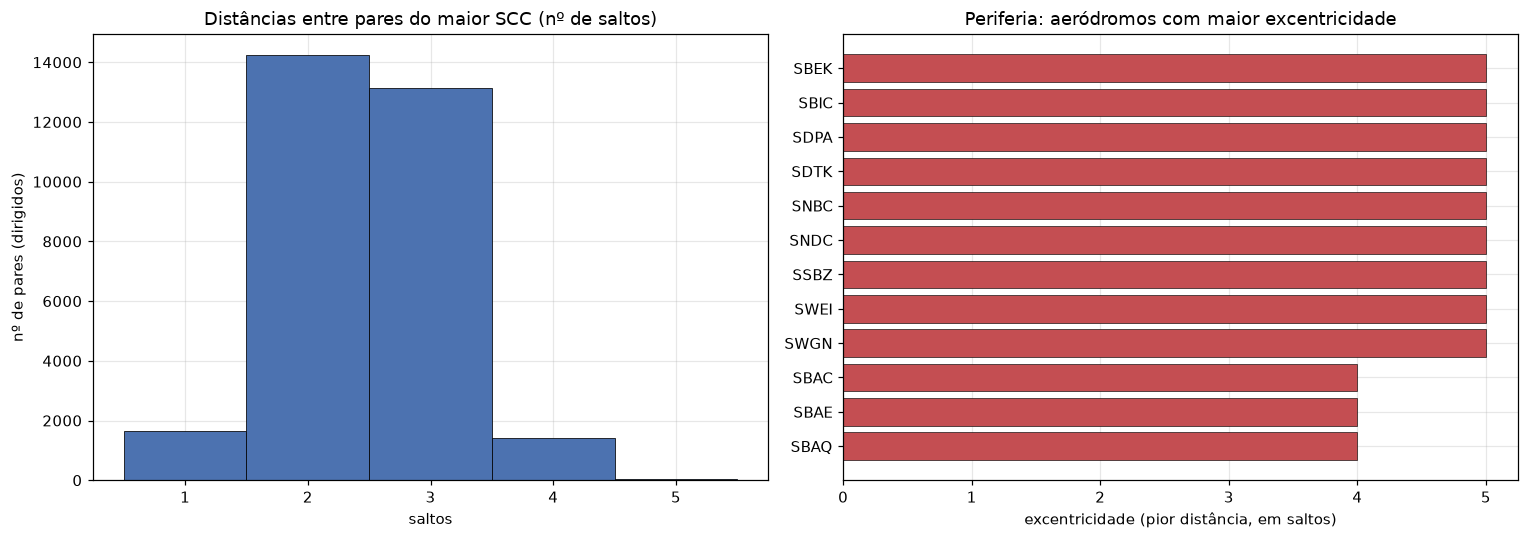

pares dirigidos no SCC: 30450 | média: 2.47 saltos
pares a 1 salto: 1659 | a 2: 14229 | a 5 (diâmetro): 27


In [4]:

# distribuição das distâncias entre pares do maior SCC
grande = sorted(M.maior_scc(g))
sub = g.subgraph(grande)
distancias = [d for origem in grande for destino, d in nx.single_source_shortest_path_length(sub, origem).items()
              if destino != origem]

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
eixos[0].hist(distancias, bins=np.arange(0.5, dist["diametro_scc"] + 1.5, 1), color="#4c72b0",
              edgecolor="black", linewidth=0.5)
eixos[0].set_title("Distâncias entre pares do maior SCC (nº de saltos)")
eixos[0].set_xlabel("saltos"); eixos[0].set_ylabel("nº de pares (dirigidos)")

perif = tabela_ecc.head(12).iloc[::-1]
eixos[1].barh(perif.icao, perif.excentricidade, color="#c44e52", edgecolor="black", linewidth=0.4)
eixos[1].set_title("Periferia: aeródromos com maior excentricidade")
eixos[1].set_xlabel("excentricidade (pior distância, em saltos)")
fig.tight_layout()
fig.savefig(FIGURAS / "08_distancias_excentricidade.png", bbox_inches="tight")
plt.show()

print(f"pares dirigidos no SCC: {len(distancias)} | média: {np.mean(distancias):.2f} saltos")
print(f"pares a 1 salto: {distancias.count(1)} | a 2: {distancias.count(2)} | "
      f"a {dist['diametro_scc']} (diâmetro): {distancias.count(dist['diametro_scc'])}")


**Leitura.** Comprimento médio de 2,47 saltos e diâmetro 5: qualquer aeródromo alcança
qualquer outro em **poucos voos** — a malha é de mundo pequeno, esparsa e com atalhos bem
colocados (os hubs). A distribuição é esmagadoramente rasa: dos 30.450 pares dirigidos do
maior SCC, 1.659 estão a 1 salto e 14.229 a 2; só **27 pares** (0,09%) exigem o pior caso
(5 saltos). O centro (raio 3) tem 24 aeródromos; a periferia (excentricidade 5) tem nove,
mistura de campos amazônicos (Jacareacanga, Itacoatiara, Eirunepé, Redenção) com
destinos "de lazer" de malha curta (Paraty, Búzios, Mangaratiba) — a "última milha" da
malha está tanto na fronteira quanto na rota de fim de semana. O diâmetro mede o pior
caso: é ele que a pergunta de contingência persegue.

## 3. Centralidades (semana 4)

As quatro medidas do curso, com as variantes de direção que o digrafo exige:

| medida | pergunta no domínio |
|---|---|
| grau (entrada/saída) | com quantos aeródromos o aeroporto compartilha rota |
| proximidade (entrada/saída) | quão rápido os outros chegam nele / ele chega nos outros |
| intermediação | quanto dos caminhos mais curtos do país passa por ele |
| autovetor (entrada/saída) | quão "bem conectado aos bem conectados" ele é |

`weight` em intermediação é **custo**, não importância: as variantes com distância (km) e
com frequência (1/decolagens) entram na subseção seguinte.

In [5]:

cent = M.tabela_centralidades(g)
cent.to_csv(RESULTADOS / "centralidades.csv", index=False)

top_inter = cent.sort_values("intermediacao", ascending=False).head(12)
top_inter[["icao", "nome", "uf", "grau_total", "passageiros_total", "intermediacao",
           "proximidade_entrada", "autovetor_entrada"]].round(4)


,icao,nome,uf,grau_total,passageiros_total,intermediacao,proximidade_entrada,autovetor_entrada
5,SBKP,CAMPINAS,SP,181,11654910.0,0.2519,0.6679,0.2665
4,SBCF,CONFINS,MG,156,12339499.0,0.1997,0.6458,0.2519
27,SBEG,MANAUS,AM,90,2961478.0,0.1805,0.5556,0.1449
1,SBRF,RECIFE,PE,108,9242285.0,0.1169,0.5719,0.2050
32,SBBE,BELÉM,PA,76,3714377.0,0.0923,0.5368,0.1363
17,SBGR,GUARULHOS,SP,134,29872406.0,0.0746,0.6055,0.2450
15,SBFZ,FORTALEZA,CE,73,5556875.0,0.0567,0.5319,0.1530
35,SBCT,SÃO JOSÉ DOS PINHAIS,PR,84,5846695.0,0.0513,0.5573,0.1856
21,SBSV,SALVADOR,BA,76,7304233.0,0.0505,0.5418,0.1744
11,SBJD,JUNDIAÍ,SP,50,0.0,0.0454,0.4667,0.1039


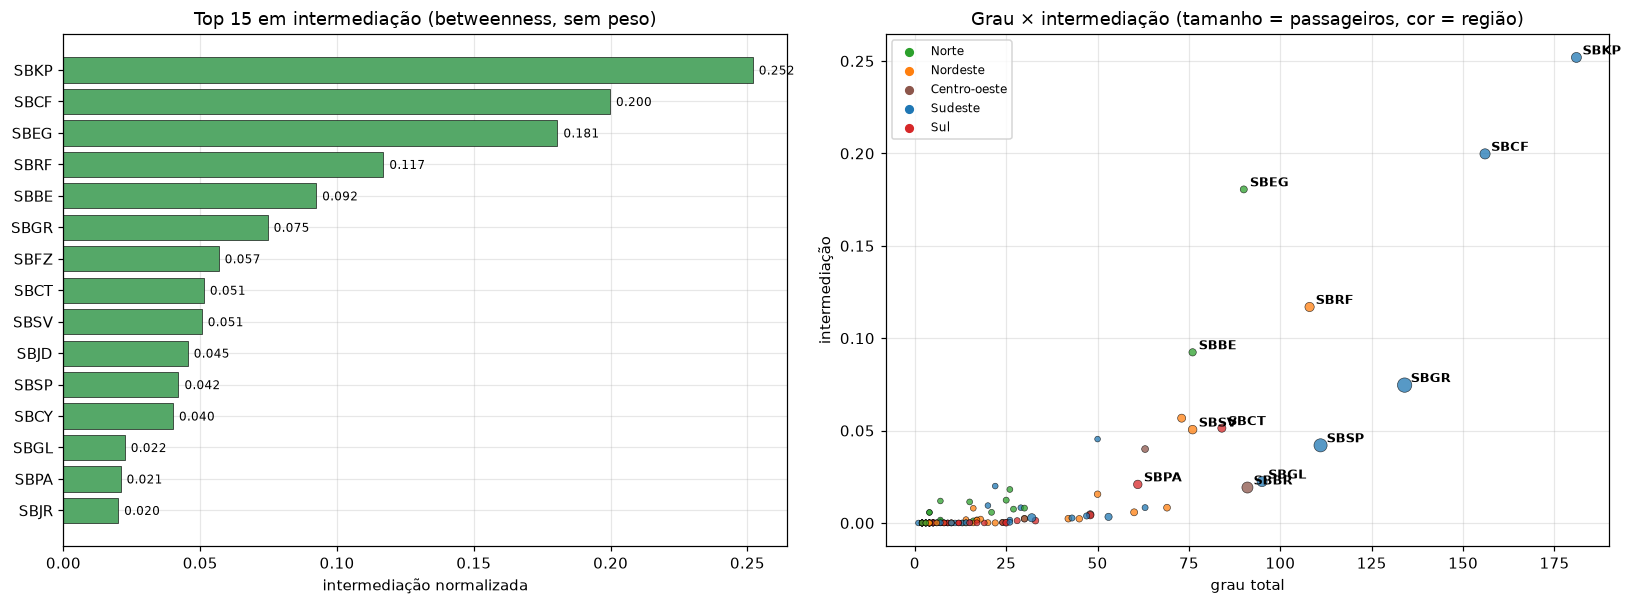

In [6]:

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.6))

ordem_b = cent.sort_values("intermediacao", ascending=False).head(15).iloc[::-1]
eixos[0].barh(ordem_b.icao, ordem_b.intermediacao, color="#55a868", edgecolor="black", linewidth=0.4)
for icao, valor in zip(ordem_b.icao, ordem_b.intermediacao):
    eixos[0].annotate(f"{valor:.3f}", (valor, icao), xytext=(4, -3), textcoords="offset points", fontsize=8)
eixos[0].set_title("Top 15 em intermediação (betweenness, sem peso)")
eixos[0].set_xlabel("intermediação normalizada")

dispersao = eixos[1].scatter(cent.grau_total, cent.intermediacao, s=14 + cent.passageiros_total / 4e5,
                             c=[regioes[r] for r in cent.regiao], alpha=0.75, edgecolor="black", linewidth=0.4)
for icao in ["SBKP", "SBCF", "SBEG", "SBGR", "SBSP", "SBRF", "SBBE", "SBBR", "SBCT", "SBSV", "SBPA", "SBGL"]:
    linha = cent[cent.icao == icao].iloc[0]
    eixos[1].annotate(icao, (linha.grau_total, linha.intermediacao), xytext=(4, 2),
                      textcoords="offset points", fontsize=8.5, fontweight="bold")
eixos[1].set_title("Grau × intermediação (tamanho = passageiros, cor = região)")
eixos[1].set_xlabel("grau total"); eixos[1].set_ylabel("intermediação")
for regiao, cor in regioes.items():
    eixos[1].scatter([], [], color=cor, label=regiao.capitalize(), s=25)
eixos[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "09_centralidades.png", bbox_inches="tight")
plt.show()


**Leitura.** Os gargalos são `SBKP` (Campinas, 0,252), `SBCF` (Confins, 0,200) e `SBEG`
(Manaus, 0,181) — **não** os maiores volumes. SBGR tem 29,9 milhões de passageiros e grau
alto, mas intermediação de apenas 0,075: volume não é gargalo; **posição** é. A dispersão
confirma: grau e intermediação não são a mesma coisa (nuvem, não reta), e a cor mostra
que o gargalo do Norte (SBEG) puxa a periferia amazônica.

Duas notas de honestidade dessa tabela:

1. **SBJD (Jundiaí)** entra no top-10 de intermediação (0,045) com **zero passageiro pago**
   no ano: as rotas dele são operações não comerciais (posicionamento/instrução), que na
   medida sem peso funcionam como atalhos entre aeródromos paulistas. É o lembrete de que
   a intermediação por saltos conta **todo** voo registrado — a variante por frequência
   rebaixa SBJD (0,045 → 0,039) e mostra que o efeito é de rotas curtas e raras.
2. SBEG tem intermediação **alta com grau médio** (90): pouco conectado em número, muito
   necessário em posição — a assinatura de um "portão" regional. É o primeiro candidato
   da análise de falha.

In [7]:

variantes = M.tabela_intermediacao_variantes(g)
variantes.to_csv(RESULTADOS / "intermediacao_variantes.csv", index=False)

medidas = ["grau_entrada", "grau_saida", "proximidade_entrada", "proximidade_saida",
           "intermediacao", "autovetor_entrada", "autovetor_saida"]
correlacoes = cent[medidas].corr(method="spearman").round(3)

print("Top 6 em intermediação sob cada definição de custo:")
for coluna in ["intermediacao_saltos", "intermediacao_distancia", "intermediacao_frequencia"]:
    nomes = variantes.sort_values(coluna, ascending=False).head(6).icao.tolist()
    print(f"  {coluna:26s}: {'  '.join(nomes)}")

from scipy.stats import spearmanr
rho_dist = spearmanr(variantes.intermediacao_saltos, variantes.intermediacao_distancia).statistic
rho_freq = spearmanr(variantes.intermediacao_saltos, variantes.intermediacao_frequencia).statistic
print(f"\nSpearman(saltos, distância km): {rho_dist:.3f} | Spearman(saltos, frequência): {rho_freq:.3f}")


Top 6 em intermediação sob cada definição de custo:
  intermediacao_saltos      : SBKP  SBCF  SBEG  SBRF  SBBE  SBGR
  intermediacao_distancia   : SBKP  SBCF  SBEG  SBCY  SBBR  SBRF
  intermediacao_frequencia  : SBGR  SBCF  SBKP  SBEG  SBRF  SBBE



Spearman(saltos, distância km): 0.905 | Spearman(saltos, frequência): 0.656


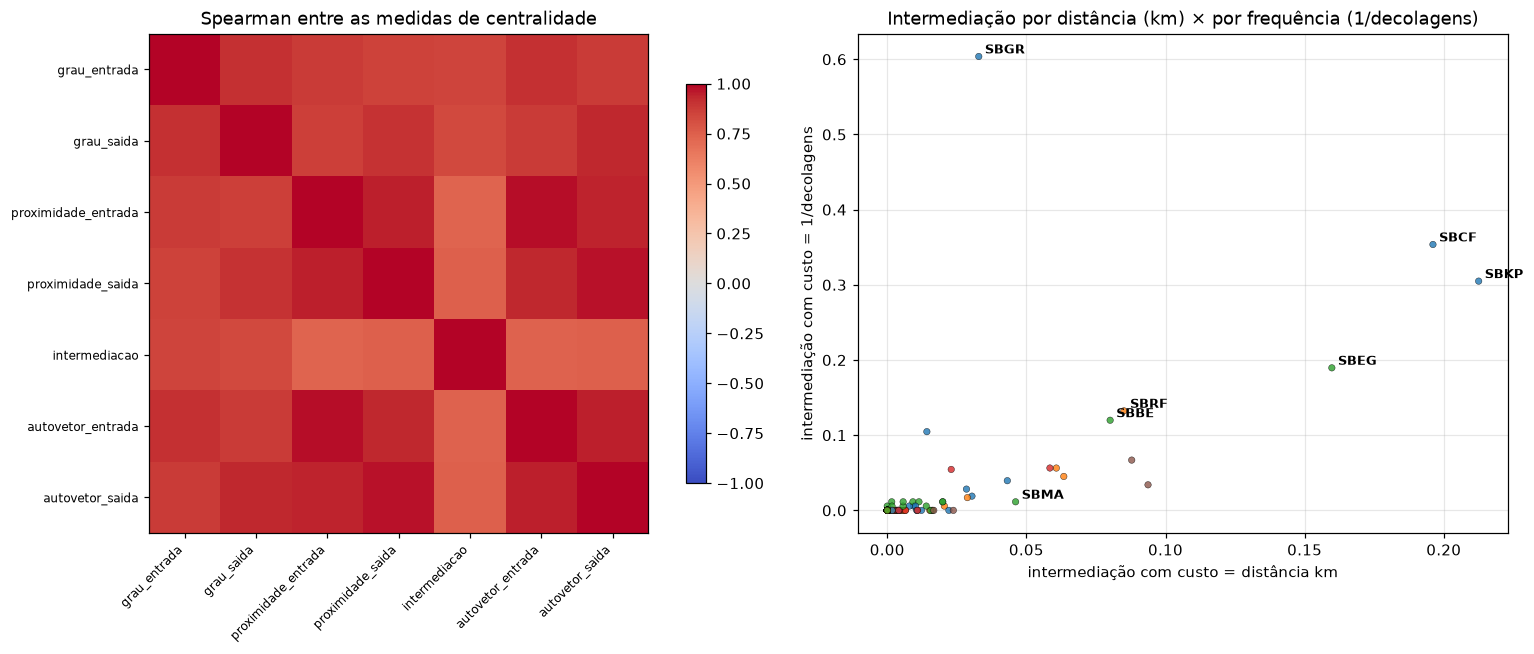

In [8]:

fig, eixos = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.15, 1]})

im = eixos[0].imshow(correlacoes, cmap="coolwarm", vmin=-1, vmax=1)
eixos[0].set_xticks(range(len(medidas)), medidas, rotation=45, ha="right", fontsize=8)
eixos[0].set_yticks(range(len(medidas)), medidas, fontsize=8)
eixos[0].set_title("Spearman entre as medidas de centralidade")
eixos[0].grid(False)
fig.colorbar(im, ax=eixos[0], shrink=0.8)

dispersao2 = eixos[1].scatter(variantes.intermediacao_distancia, variantes.intermediacao_frequencia,
                              s=18, c=[regioes[r] for r in cent.set_index("icao").loc[variantes.icao, "regiao"]],
                              alpha=0.8, edgecolor="black", linewidth=0.3)
for icao in ["SBKP", "SBCF", "SBEG", "SBGR", "SBMA", "SBBE", "SBRF"]:
    linha = variantes[variantes.icao == icao]
    if not linha.empty:
        eixos[1].annotate(icao, (linha.intermediacao_distancia.iloc[0], linha.intermediacao_frequencia.iloc[0]),
                          xytext=(4, 2), textcoords="offset points", fontsize=8.5, fontweight="bold")
eixos[1].set_title("Intermediação por distância (km) × por frequência (1/decolagens)")
eixos[1].set_xlabel("intermediação com custo = distância km")
eixos[1].set_ylabel("intermediação com custo = 1/decolagens")
fig.tight_layout()
fig.savefig(FIGURAS / "10_correlacao_medidas.png", bbox_inches="tight")
plt.show()


**Leitura.** As centralidades se dividem em dois blocos: as de grau/proximidade/autovetor
andam juntas (Spearman alto), e a intermediação é a medida que **não** se deixa substituir
(correlação baixa com as demais). Entre as variantes de intermediação:

- por **distância km** (Spearman 0,905 com a versão por saltos): SBKP, SBCF e SBEG seguem
  no topo — o gargalo topológico também é gargalo geográfico;
- por **frequência** (1/decolagens, Spearman 0,656): `SBGR` assume a liderança com 0,604 —
  quando o custo é "poucos voos", o aeroporto de maior frequência do país (Guarulhos) é o
  mais crítico, e SBEG/SBRF/SBBE ganham posições.

A diferença entre as três leituras é a resposta operacional: para o **número de voos**, o
gargalo é Guarulhos; para **passageiro que espera conexão rápida**, os portões regionais
(SBEG, SBRF, SBBE) pesam mais. Fica registrado que a escolha de custo muda o ranking — a
versão anunciada na resposta final é a sem peso (saltos), que é a medida canônica do
curso, com as variantes como sensibilidade.

## 4. Triângulos e agrupamento (semana 4)

Triângulos só existem na projeção não dirigida (o networkx não calcula clustering em
digrafo; converter tem o custo de contar ciclo dirigido como triângulo — artefato
declarado). Clustering local = fração dos vizinhos que também são vizinhos entre si.

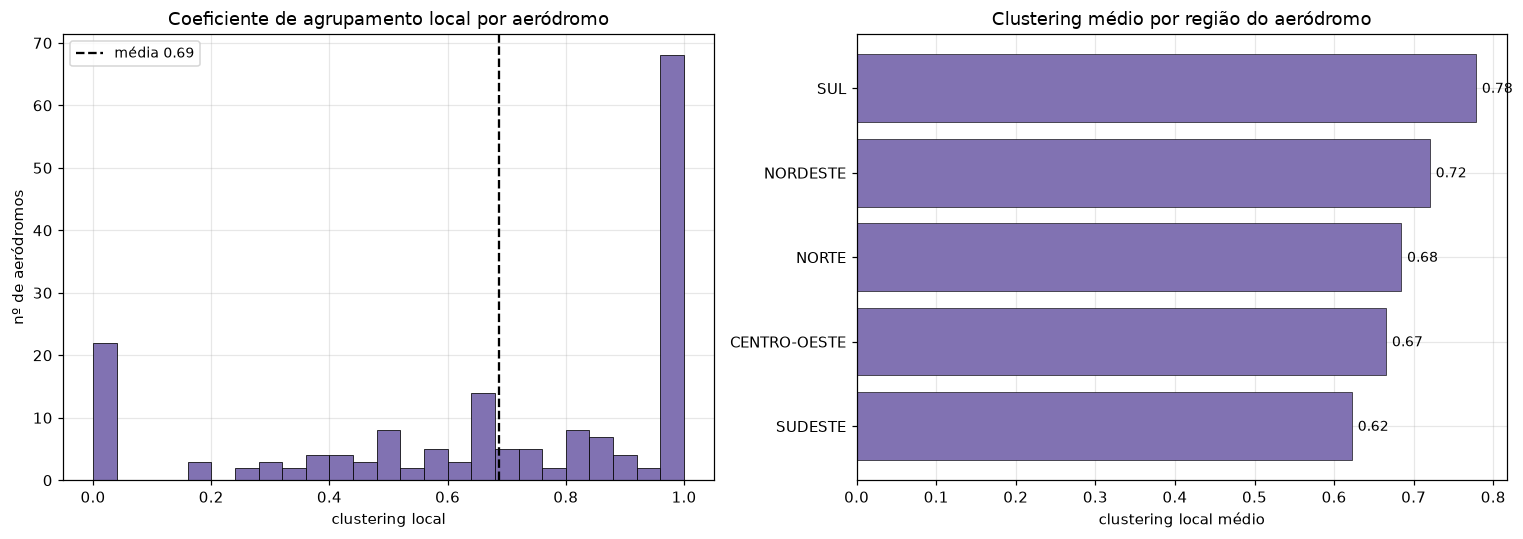

clustering médio da malha: 0.688
aeródromos com clustering = 1: 65


,aeródromos,clustering_medio,triangulos_total
regiao,,,
SUL,25,0.778,1738
NORDESTE,42,0.720,3104
NORTE,44,0.684,1237
CENTRO-OESTE,18,0.665,1228
SUDESTE,47,0.622,5221


In [9]:

clustering = M.tabela_clustering(h)
clustering.to_csv(RESULTADOS / "clustering.csv", index=False)

por_regiao_cl = (clustering.groupby("regiao")
                 .agg(aeródromos=("icao", "size"), clustering_medio=("clustering", "mean"),
                      triangulos_total=("triangulos", "sum"))
                 .sort_values("clustering_medio", ascending=False).round(3))
por_regiao_cl.to_csv(RESULTADOS / "clustering_por_regiao.csv")

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
eixos[0].hist(clustering.clustering, bins=25, color="#8172b2", edgecolor="black", linewidth=0.5)
eixos[0].axvline(clustering.clustering.mean(), color="black", linestyle="--",
                 label=f"média {clustering.clustering.mean():.2f}")
eixos[0].set_title("Coeficiente de agrupamento local por aeródromo")
eixos[0].set_xlabel("clustering local"); eixos[0].set_ylabel("nº de aeródromos")
eixos[0].legend(fontsize=9)

ordem_r = por_regiao_cl.sort_values("clustering_medio")
eixos[1].barh(ordem_r.index, ordem_r.clustering_medio, color="#8172b2", edgecolor="black", linewidth=0.4)
for regiao, valor in zip(ordem_r.index, ordem_r.clustering_medio):
    eixos[1].annotate(f"{valor:.2f}", (valor, regiao), xytext=(4, -3), textcoords="offset points", fontsize=9)
eixos[1].set_title("Clustering médio por região do aeródromo")
eixos[1].set_xlabel("clustering local médio")
fig.tight_layout()
fig.savefig(FIGURAS / "11_clustering.png", bbox_inches="tight")
plt.show()

print(f"clustering médio da malha: {clustering.clustering.mean():.3f}")
print(f"aeródromos com clustering = 1: {(clustering.clustering == 1).sum()}")
por_regiao_cl


**Leitura.** Clustering médio 0,688 é **alto**, mas engana em parte: 65 aeródromos de grau
baixo têm clustering = 1 por construção (com dois vizinhos que se conhecem, o triângulo
fecha). A leitura útil é a diferença por região — e ela inverte a intuição: o **SUL** tem
o maior clustering médio (0,778) e o **SUDESTE** o menor (0,622). Faz sentido: no Sudeste
os aeroportos são conectados a vizinhos espalhados pelo país (São Paulo fala com Manaus,
Recife, Porto Alegre — vizinhos que não falam entre si); no Sul, a malha é regional e
fechada (os vizinhos de Porto Alegre também são vizinhos de Florianópolis). Clustering
mede "todo mundo fala com todo mundo" — coesão regional, não centralidade.

## 5. Decomposição em núcleos (semana 5)

O k-core é o maior subgrafo em que todo nó tem grau ≥ k **dentro** do subgrafo; o core
number é o maior k que sobrevive com o nó; a degeneração é o maior core number. É
"descascar a cebola": o k-shell externo cai primeiro; o miolo é o que aguenta.

In [10]:

core_nx = nx.core_number(h)
core_manual = M.core_numbers_manual(h)
print("implementação manual == networkx:", core_manual == core_nx)

kcore = M.tabela_kcore(h)
kcore.to_csv(RESULTADOS / "kcore.csv", index=False)
degeneracao = max(core_nx.values())
print("degeneração (maior core number):", degeneracao)
print("tamanho do k-core para k = 1..degeneração:")
for k in range(1, degeneracao + 1):
    print(f"  k={k:2d}: {len(M.k_core_manual(h, k)):3d} nós")


implementação manual == networkx: True
degeneração (maior core number): 18
tamanho do k-core para k = 1..degeneração:
  k= 1: 176 nós
  k= 2: 154 nós
  k= 3: 112 nós
  k= 4:  86 nós
  k= 5:  77 nós
  k= 6:  70 nós
  k= 7:  68 nós
  k= 8:  59 nós
  k= 9:  55 nós
  k=10:  51 nós
  k=11:  47 nós
  k=12:  42 nós
  k=13:  41 nós
  k=14:  38 nós
  k=15:  32 nós
  k=16:  24 nós
  k=17:  24 nós
  k=18:  24 nós


**Teste de sanidade:** a implementação manual (descascamento por definição, seção 17 do
resumo teórico) tem de reproduzir `nx.core_number` — e reproduz. Números:


In [11]:

kcore.head(15)


,icao,core_number,grau,regiao
0,SBKP,18,93,SUDESTE
1,SBCF,18,84,SUDESTE
2,SBGR,18,69,SUDESTE
3,SBSP,18,60,SUDESTE
4,SBRF,18,58,NORDESTE
5,SBGL,18,56,SUDESTE
6,SBEG,18,51,NORTE
7,SBBR,18,49,CENTRO-OESTE
8,SBCT,18,48,SUL
9,SBRP,18,46,SUDESTE


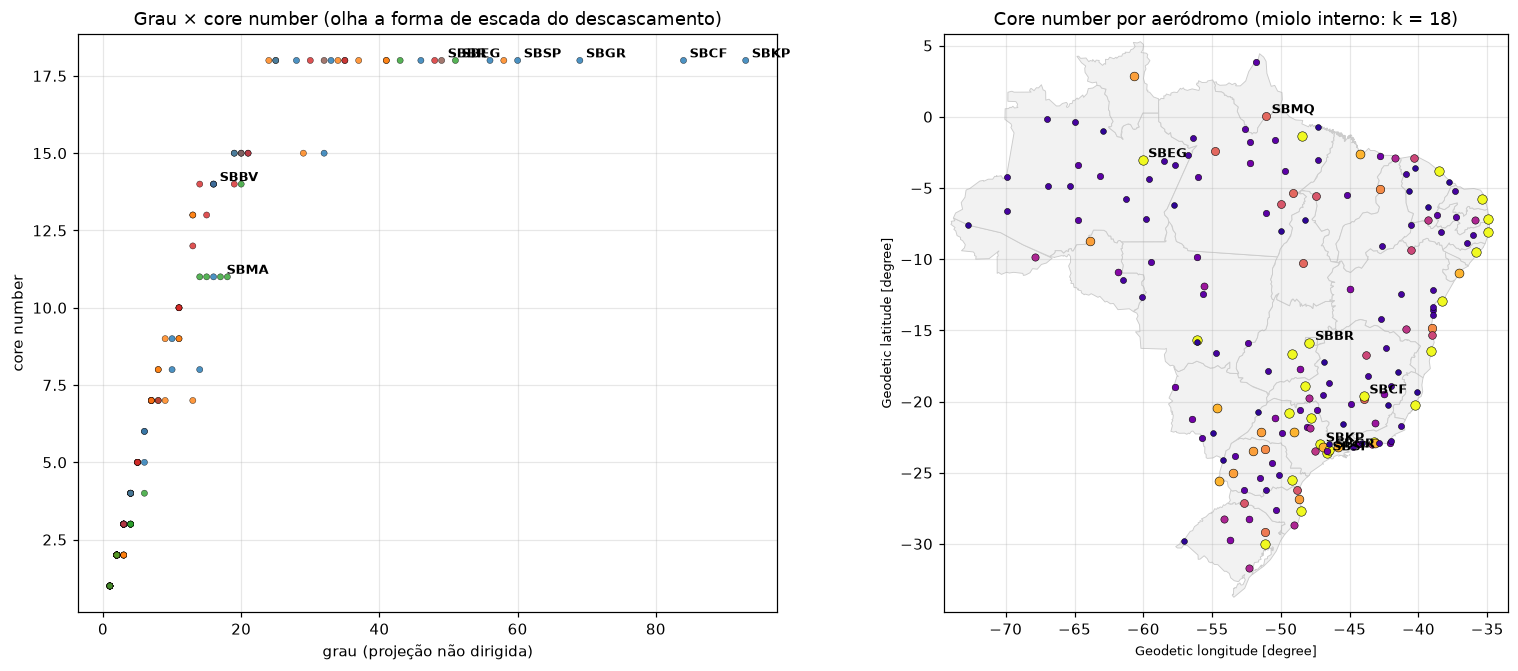

miolo (k = 18): 24 aeródromos -> SBKP, SBCF, SBGR, SBSP, SBRF, SBGL, SBEG, SBBR, SBCT, SBRP, SBBE, SBFZ, SBSV, SBPS, SBCY, SBPA, SBMO, SBVT, SBGO, SBFL, SBUL, SBJP, SBSR, SBSG
periferia (core number <= 2): 64 aeródromos


In [12]:

fig, eixos = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1, 1.15]})

eixos[0].scatter(kcore.grau, kcore.core_number, s=16, c=[regioes[r] for r in kcore.regiao],
                 alpha=0.8, edgecolor="black", linewidth=0.3)
for icao in ["SBGR", "SBSP", "SBCF", "SBBR", "SBKP", "SBEG", "SBMA", "SBBV"]:
    linha = kcore[kcore.icao == icao]
    if not linha.empty:
        eixos[0].annotate(icao, (linha.grau.iloc[0], linha.core_number.iloc[0]),
                          xytext=(4, 2), textcoords="offset points", fontsize=8.5, fontweight="bold")
eixos[0].set_title("Grau × core number (olha a forma de escada do descascamento)")
eixos[0].set_xlabel("grau (projeção não dirigida)"); eixos[0].set_ylabel("core number")

M.fundo_mapa(eixos[1])
pos = M.posicoes(g)
cmap = plt.get_cmap("plasma")
for n in g:
    eixos[1].scatter(*pos[n], color=cmap(core_nx[n] / degeneracao), s=13 + 1.4 * core_nx[n],
                     edgecolor="black", linewidth=0.35, zorder=3)
for icao in ["SBGR", "SBSP", "SBCF", "SBBR", "SBKP", "SBEG", "SBMQ"]:
    eixos[1].annotate(icao, (pos[icao][0] + 0.4, pos[icao][1] + 0.2), fontsize=8.5, fontweight="bold")
eixos[1].set_title(f"Core number por aeródromo (miolo interno: k = {degeneracao})")
eixos[1].set_xlim(-74.5, -33.5); eixos[1].set_ylim(-34.8, 5.8); eixos[1].set_aspect(1.035)
fig.tight_layout()
fig.savefig(FIGURAS / "12_kcore.png", bbox_inches="tight")
plt.show()

miolo = kcore[kcore.core_number == degeneracao]
print(f"miolo (k = {degeneracao}): {len(miolo)} aeródromos -> {', '.join(miolo.icao)}")
periferia_1 = kcore[kcore.core_number <= 2]
print(f"periferia (core number <= 2): {len(periferia_1)} aeródromos")


**Leitura.** O miolo do descascamento tem **24 aeródromos** — os hubs das cinco regiões
mais os terminais do eixo SP–RJ–BSB: é o "tronco denso" da malha. Note a diferença de
recado: centralidade diz "quem é importante"; core-number diz "quem aguenta viver
apertado" — um aeródromo pode ser gargalo (intermediação alta) sem estar no miolo se as
rotas dele ligam duas partes separadas com pouco entrelaçamento. E a base da cebola é
grande: **64 dos 176 aeródromos têm core number ≤ 2** — um terço da malha vive de uma ou
duas rotas, e é essa cauda que a análise de falha vai expor primeiro.

## 6. k-truss: coesão com testemunha (semana 5)

Um k-truss exige que toda **aresta** participe de k−2 triângulos — é mais rigoroso que o
k-core (o grau pode vir de vizinhos que não se conhecem).

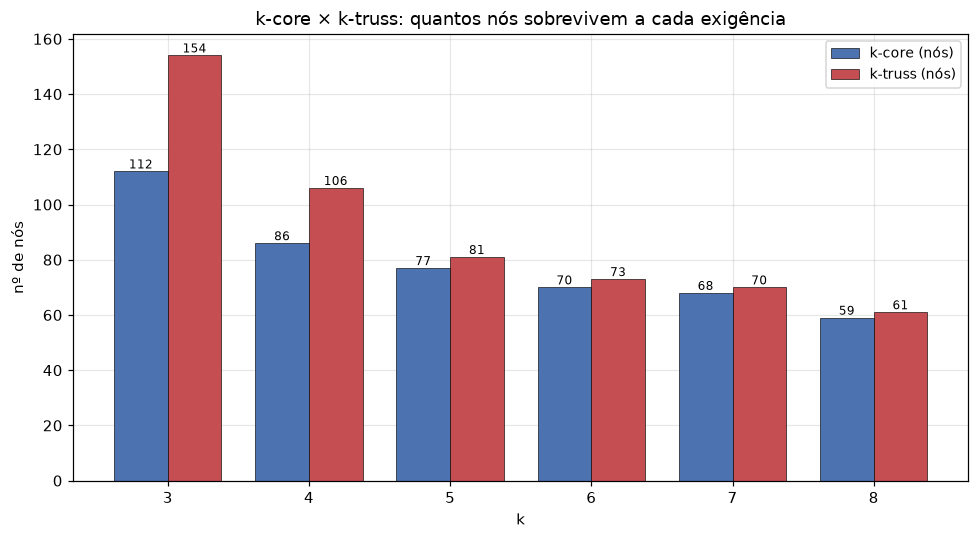

,k,k_core_nos,k_truss_nos,k_truss_arestas
0,3,112,154,964
1,4,86,106,864
2,5,77,81,791
3,6,70,73,754
4,7,68,70,738
5,8,59,61,675


In [13]:

ktuss = M.tabela_ktuss(h, range(3, 9))
ktuss.to_csv(RESULTADOS / "ktuss.csv", index=False)

comparacao = []
for k in range(3, 9):
    comparacao.append({"k": k, "k_core_nos": len(M.k_core_manual(h, k)),
                       "k_truss_nos": int(ktuss[ktuss.k == k].nos.iloc[0]),
                       "k_truss_arestas": int(ktuss[ktuss.k == k].arestas.iloc[0])})
comparacao = pd.DataFrame(comparacao)
comparacao.to_csv(RESULTADOS / "kcore_vs_ktuss.csv", index=False)

fig, eixo = plt.subplots(figsize=(9, 5))
largura = 0.38
eixo.bar(comparacao.k - largura / 2, comparacao.k_core_nos, largura, label="k-core (nós)",
         color="#4c72b0", edgecolor="black", linewidth=0.4)
eixo.bar(comparacao.k + largura / 2, comparacao.k_truss_nos, largura, label="k-truss (nós)",
         color="#c44e52", edgecolor="black", linewidth=0.4)
for linha in comparacao.itertuples():
    eixo.annotate(str(linha.k_core_nos), (linha.k - largura / 2, linha.k_core_nos), ha="center",
                  va="bottom", fontsize=8)
    eixo.annotate(str(linha.k_truss_nos), (linha.k + largura / 2, linha.k_truss_nos), ha="center",
                  va="bottom", fontsize=8)
eixo.set_title("k-core × k-truss: quantos nós sobrevivem a cada exigência")
eixo.set_xlabel("k"); eixo.set_ylabel("nº de nós"); eixo.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "13_ktuss.png", bbox_inches="tight")
plt.show()
comparacao


**Leitura.** O k-truss encolhe mais devagar que o k-core: no k=3 mantém 154 nós e 964
arestas (o k-core tem 112); no k=7 sobrevive com 70 nós (contra 68 do k-core no mesmo k);
e no k=8 ainda restam 61 nós em 675 arestas. O k-core vai muito mais longe (até k=18)
porque só exige grau; o truss exige **testemunha triangular** em cada aresta e por isso
"para antes" — mas o que resta nele é um bloco coeso de verdade no centro da malha,
o mesmo grupo do miolo do k-core. Dois métodos, mesma conclusão sobre onde está o
núcleo.

## 7. Semana 6 — bipartido aeroporto × empresa e projeção por Jaccard

O curso pede um par bipartido, matriz de incidência, projeção e Jaccard. Aqui a leitura é
operacional: **dois aeroportos ligados às mesmas empresas aéreas são substitutos
operacionais** — se um sai do ar, quem opera a região já está no outro. A projeção usa
Jaccard (interseção sobre união), não contagem bruta, porque contagem bruta só premiaria
os aeroportos com muitas empresas.

bipartido: 176 aeroportos x 73 empresas | 721 ligações


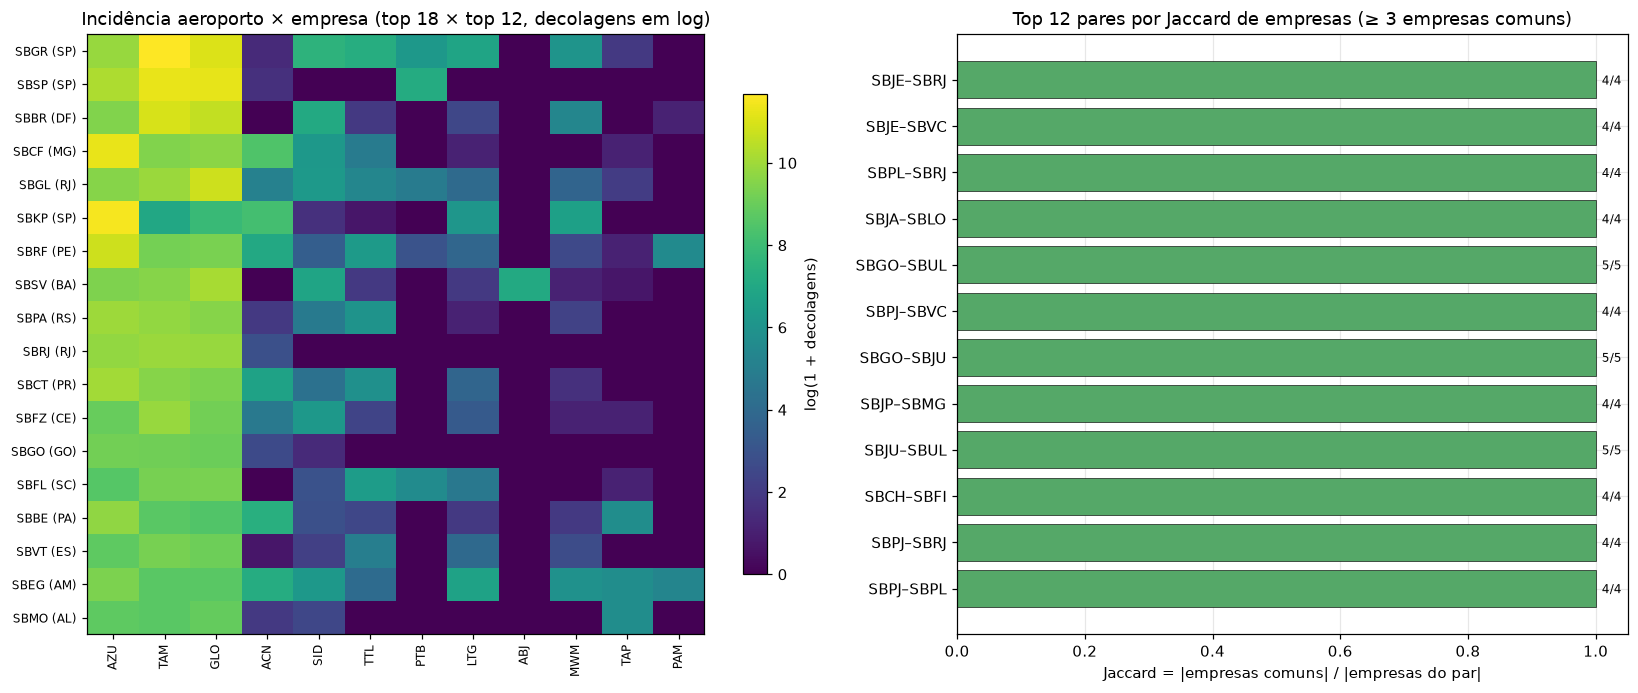

empresas que operam mais aeroportos:
  ACN: 121 aeroportos
  AZU: 110 aeroportos
  GLO: 69 aeroportos
  TAM: 62 aeroportos
  SID: 31 aeroportos
  MWM: 20 aeroportos


In [14]:

voos = M.recortar(M.carregar_bruto())
b = M.bipartido_aeroporto_empresa(voos)
n_aero = sum(1 for n in b if n[0] == "aeroporto")
n_emp = sum(1 for n in b if n[0] == "empresa")
print(f"bipartido: {n_aero} aeroportos x {n_emp} empresas | {b.number_of_edges()} ligações")

empresas_volume = (voos.assign(empresa=voos["EMPRESA (SIGLA)"])
                   .groupby("empresa")["DECOLAGENS"].sum().sort_values(ascending=False))
top_emp = list(empresas_volume.head(12).index)
graus = pd.read_csv(RESULTADOS / "graus.csv")
top_aero = list(graus.sort_values("passageiros_total", ascending=False).head(18).icao)

matriz = np.zeros((len(top_aero), len(top_emp)))
for i, a in enumerate(top_aero):
    for j, e in enumerate(top_emp):
        if b.has_edge(("aeroporto", a), ("empresa", e)):
            matriz[i, j] = b[("aeroporto", a)][("empresa", e)]["decolagens"]

projecao = M.jaccard_empresas(b, minimo_empresas=3)
projecao.to_csv(RESULTADOS / "projecao_empresas_top.csv", index=False)

fig, eixos = plt.subplots(1, 2, figsize=(15, 6.4), gridspec_kw={"width_ratios": [1.15, 1]})
im = eixos[0].imshow(np.log1p(matriz), cmap="viridis", aspect="auto")
eixos[0].set_xticks(range(len(top_emp)), top_emp, rotation=90, fontsize=8)
eixos[0].set_yticks(range(len(top_aero)), [f"{a} ({uf})" for a, uf in zip(top_aero, graus.set_index("icao").loc[top_aero, "uf"])], fontsize=8)
eixos[0].set_title("Incidência aeroporto × empresa (top 18 × top 12, decolagens em log)")
eixos[0].grid(False)
fig.colorbar(im, ax=eixos[0], shrink=0.8, label="log(1 + decolagens)")

top_proj = projecao.head(12).iloc[::-1]
rotulos_proj = [f"{a}–{c}" for a, c in zip(top_proj.aeroporto_a, top_proj.aeroporto_b)]
eixos[1].barh(rotulos_proj, top_proj.jaccard, color="#55a868", edgecolor="black", linewidth=0.4)
for i, linha in enumerate(top_proj.itertuples()):
    eixos[1].annotate(f"{int(linha.empresas_comuns)}/{int(linha.empresas_uniao)}",
                      (linha.jaccard, i), xytext=(4, -3), textcoords="offset points", fontsize=8)
eixos[1].set_title("Top 12 pares por Jaccard de empresas (≥ 3 empresas comuns)")
eixos[1].set_xlabel("Jaccard = |empresas comuns| / |empresas do par|")
fig.tight_layout()
fig.savefig(FIGURAS / "14_bipartido_empresas.png", bbox_inches="tight")
plt.show()

print("empresas que operam mais aeroportos:")
aeroportos_por_empresa = {nome: len(list(b.neighbors(("empresa", nome)))) for _, nome in
                          (n for n in b.nodes if n[0] == "empresa")}
for nome, qtd in sorted(aeroportos_por_empresa.items(), key=lambda x: -x[1])[:6]:
    print(f"  {nome}: {qtd} aeroportos")


**Leitura.** O bipartido mostra a estrutura de quem opera onde. No recorte doméstico de
2025 há **73 empresas** ativas (106 no arquivo bruto, com as internacionais): a **ACN**
aparece com a maior capilaridade (121 aeródromos), seguida de **AZU** (110), **GLO** (69)
e **TAM** (62) — a malha de cauda (aeródromos pequenos) está nas duas primeiras, e é ali
que o corte de uma empresa dói. Os pares com Jaccard = 1 no topo da projeção são
**aeródromos pequenos atendidos exatamente pelas mesmas poucas empresas** (SBJE–SBRJ,
SBGO–SBUL, SBJU–SBUL: 4/4 ou 5/5 empresas em comum — substituto operacional clássico do
interior). Nos grandes o Jaccard de empresas despenca (cada um tem mix próprio de
operador) — por isso a pergunta de "quem substitui quem" para o passageiro precisa da
vizinhança de **rotas**, não de operadoras: é o Jaccard de vizinhança, a seguir.

## 8. Jaccard de vizinhança — quem é substituto de quem

Jaccard entre os conjuntos de vizinhos das duas pontas de cada rota (descontando as
próprias pontas, convenção para predição de aresta). J alto = as duas pontas conectam
"o mesmo mundo": derrubar uma, a outra absorve o papel na rede.

In [15]:

jv = M.jaccard_vizinhanca(h)
jv.to_csv(RESULTADOS / "jaccard_vizinhanca.csv", index=False)
grandes = jv[(jv.grau_origem >= 8) & (jv.grau_destino >= 8)].copy()
print(f"pares com grau >= 8 nas duas pontas: {len(grandes)}")
grandes.head(12).round(4)


pares com grau >= 8 nas duas pontas: 696


,origem,destino,grau_origem,grau_destino,vizinhos_comuns,vizinhos_uniao,jaccard,decolagens
7,SBGL,SBGR,56,69,52,71,0.7324,10539.0
8,SBBR,SBGL,49,56,43,60,0.7167,4997.0
9,SBSP,SBGR,60,69,53,74,0.7162,164.0
10,SBJU,SBPL,8,11,7,10,0.7000,1.0
11,SBMO,SBJP,34,25,23,34,0.6765,45.0
16,SBBR,SBGR,49,69,46,70,0.6571,9930.0
17,SBKP,SBGR,93,69,62,98,0.6327,717.0
18,SBSP,SBRP,60,46,40,64,0.6250,2376.0
19,SBCF,SBGR,84,69,58,93,0.6237,10686.0
20,SBJP,SBSG,25,24,18,29,0.6207,8.0


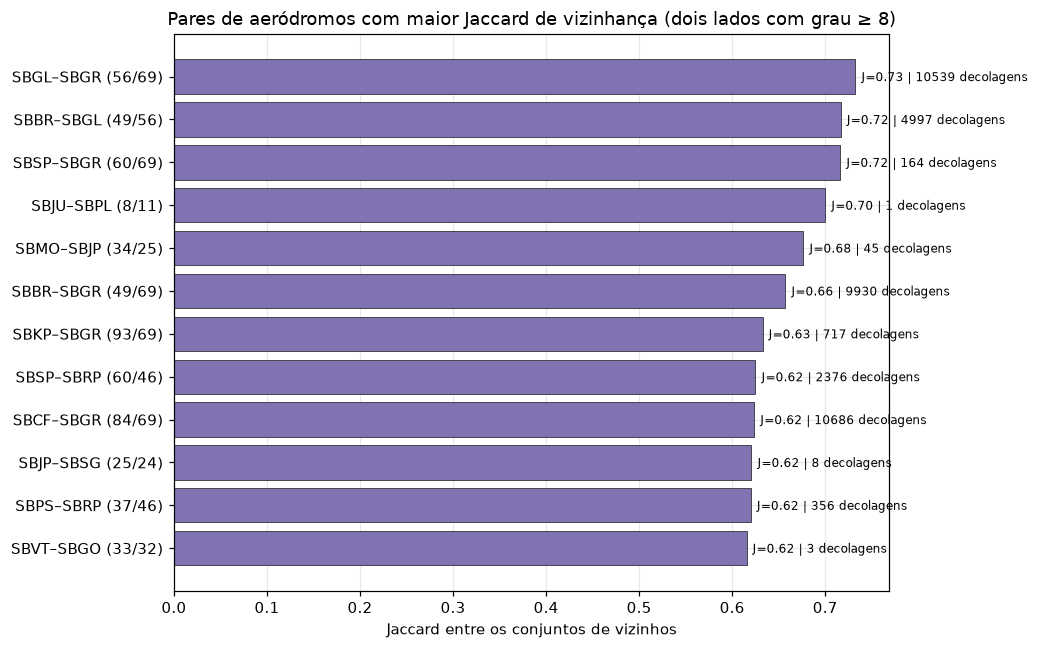

In [16]:

top_jv = grandes.head(12).iloc[::-1]
rotulos_jv = [f"{a}–{c} ({ga}/{gc})" for a, c, ga, gc in
              zip(top_jv.origem, top_jv.destino, top_jv.grau_origem, top_jv.grau_destino)]
fig, eixo = plt.subplots(figsize=(9.5, 6))
eixo.barh(rotulos_jv, top_jv.jaccard, color="#8172b2", edgecolor="black", linewidth=0.4)
for i, linha in enumerate(top_jv.itertuples()):
    eixo.annotate(f"J={linha.jaccard:.2f} | {int(linha.decolagens)} decolagens", (linha.jaccard, i),
                  xytext=(4, -3), textcoords="offset points", fontsize=8)
eixo.set_title("Pares de aeródromos com maior Jaccard de vizinhança (dois lados com grau ≥ 8)")
eixo.set_xlabel("Jaccard entre os conjuntos de vizinhos")
fig.tight_layout()
fig.savefig(FIGURAS / "15_jaccard_vizinhanca.png", bbox_inches="tight")
plt.show()


**Leitura.** Os pares do tronco Sudeste–Centro-Oeste dominam o topo:

- `SBGL–SBGR` (Galeão–Guarulhos): J = 0,73 — **52 dos 71 destinos são comuns**, com 10,5
  mil decolagens no par. Se Galeão fecha, Guarulhos já fala com quase todo o mundo dele:
  a malha não perde destinos, perde capacidade;
- `SBBR–SBGL` (0,72) e `SBCF–SBGR` (0,62; 10,7 mil decolagens): o mesmo padrão no eixo
  Brasília–Rio–Confins.

Dois cuidados que a própria tabela resolve:

1. `SBSP–SBGR` tem J = 0,72, mas apenas **164 decolagens** no ano: J alto não significa
   rota movimentada — significa **vizinhanças parecidas**. Os dois são o mesmo portão de
   São Paulo (quase não há voo direto entre eles); para capacidade, leia a coluna de
   decolagens junto.
2. Pares como `SBJU–SBPL` (J = 0,70 com 1 decolagem) ainda aparecem com o corte de grau
   ≥ 8, mas são cauda: J alto com volume desprezível não é redundância útil.

A leitura para contingência: o Sudeste concentra **redundância de destinos**; o Norte,
como a análise de falha mostrará, concentra o oposto.

## 9. Esqueleto por limiar — o tronco que não pode cair (semana 6)

Ideia da semana: manter as arestas mais pesadas até cobrir uma fração do total e medir o
que resta. Se 80% dos voos estão em poucas rotas, **esse é o tronco** — a estrutura cuja
perda fragmenta o país.

In [17]:

fracoes = [round(0.05 * i, 2) for i in range(1, 21)]  # 5% a 100%, passo de 5
esq = M.esqueleto_limiar(g, fracoes)
esq.to_csv(RESULTADOS / "esqueleto_limiar.csv", index=False)
esq.round(4)


,fracao_alvo,fracao_real,arestas,nos,nos_com_conexao,componentes_fracos,maior_wcc,maior_scc,decolagens_cobertas
0,0.05,0.0563,3,176,3,174,3,2,45242.0
1,0.10,0.1074,8,176,5,172,5,5,86244.0
2,0.15,0.1558,14,176,8,169,8,8,125129.0
3,0.20,0.2015,21,176,10,167,10,10,161813.0
4,0.25,0.2540,30,176,12,165,12,11,203934.0
5,0.30,0.3006,40,176,14,163,14,12,241374.0
6,0.35,0.3534,53,176,18,159,18,17,283738.0
7,0.40,0.4019,66,176,20,157,20,18,322700.0
8,0.45,0.4503,81,176,21,156,21,21,361587.0
9,0.50,0.5001,98,176,22,155,22,22,401507.0


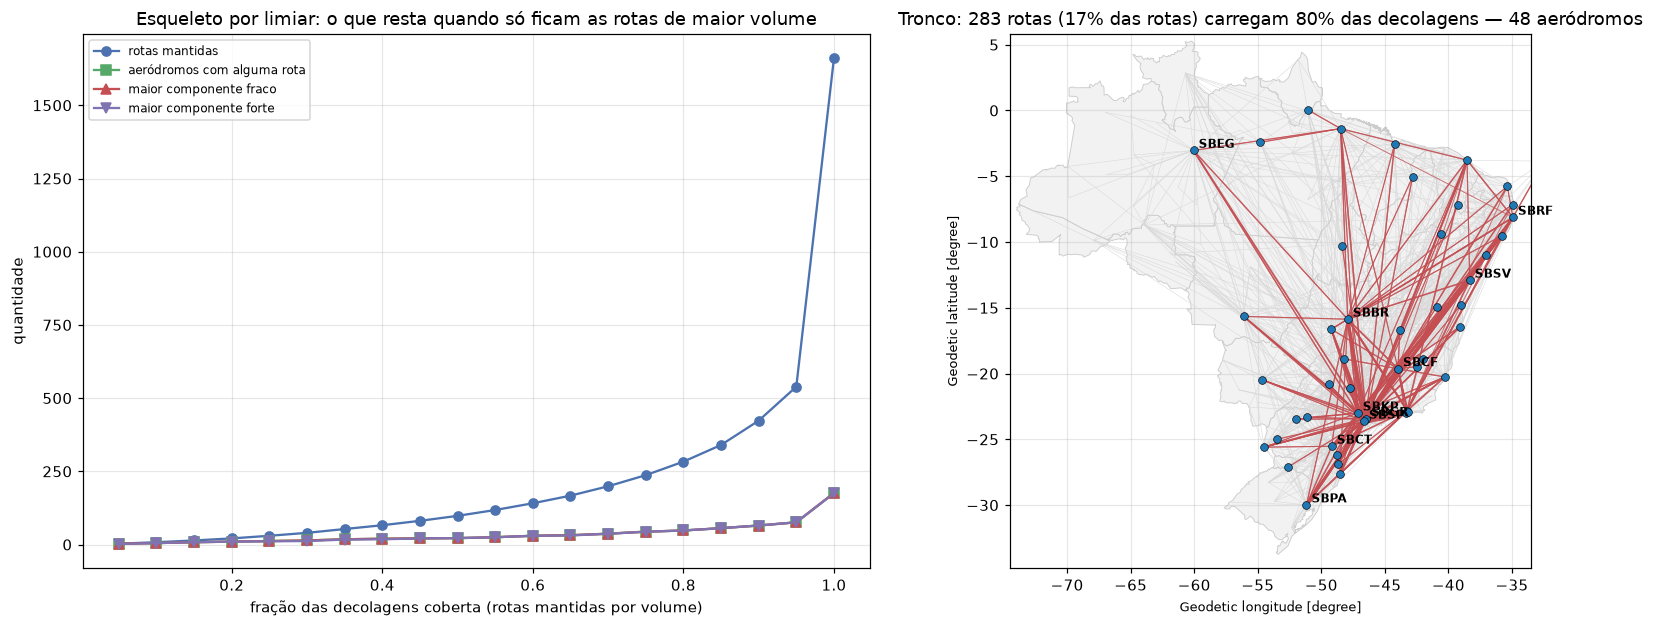

tronco em 80%: 283 rotas | 48 aeródromos | 27% dos nós
maior WCC do tronco: 48 nós


In [18]:

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.1, 1]})
eixos[0].plot(esq.fracao_alvo, esq.arestas, marker="o", color="#4c72b0", label="rotas mantidas")
eixos[0].plot(esq.fracao_alvo, esq.nos_com_conexao, marker="s", color="#55a868", label="aeródromos com alguma rota")
eixos[0].plot(esq.fracao_alvo, esq.maior_wcc, marker="^", color="#c44e52", label="maior componente fraco")
eixos[0].plot(esq.fracao_alvo, esq.maior_scc, marker="v", color="#8172b2", label="maior componente forte")
eixos[0].set_xlabel("fração das decolagens coberta (rotas mantidas por volume)")
eixos[0].set_ylabel("quantidade")
eixos[0].set_title("Esqueleto por limiar: o que resta quando só ficam as rotas de maior volume")
eixos[0].legend(fontsize=8)

arestas_ordenadas = sorted(g.edges(data=True), key=lambda e: -e[2]["decolagens"])
total_dec = sum(d["decolagens"] for _, _, d in arestas_ordenadas)
acumulado = 0.0
tronco = []
for u, v, d in arestas_ordenadas:
    if acumulado >= 0.8 * total_dec:
        break
    tronco.append((u, v, d))
    acumulado += d["decolagens"]
nos_tronco = sorted({x for u, v, _ in tronco for x in (u, v)})

M.fundo_mapa(eixos[1])
for u, v, d in h.edges(data=True):
    eixos[1].plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#d9d9d9",
                  linewidth=0.35, zorder=1)
peso_max = max(d["decolagens"] for _, _, d in tronco)
for u, v, d in tronco:
    eixos[1].plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#c44e52",
                  alpha=0.75, linewidth=0.5 + 3.2 * d["decolagens"] / peso_max, zorder=2)
eixos[1].scatter([pos[n][0] for n in nos_tronco], [pos[n][1] for n in nos_tronco],
                 s=26, color="#1f77b4", edgecolor="black", linewidth=0.4, zorder=3)
for icao in ["SBGR", "SBSP", "SBKP", "SBCF", "SBBR", "SBSV", "SBRF", "SBEG", "SBPA", "SBCT"]:
    eixos[1].annotate(icao, (pos[icao][0] + 0.4, pos[icao][1] + 0.2), fontsize=8, fontweight="bold")
eixos[1].set_title(f"Tronco: {len(tronco)} rotas ({100 * len(tronco) / g.number_of_edges():.0f}% das rotas) "
                   f"carregam 80% das decolagens — {len(nos_tronco)} aeródromos")
eixos[1].set_xlim(-74.5, -33.5); eixos[1].set_ylim(-34.8, 5.8); eixos[1].set_aspect(1.035)
fig.tight_layout()
fig.savefig(FIGURAS / "16_esqueleto_limiar.png", bbox_inches="tight")
plt.show()

print(f"tronco em 80%: {len(tronco)} rotas | {len(nos_tronco)} aeródromos | "
      f"{len(nos_tronco) / g.number_of_nodes():.0%} dos nós")
print(f"maior WCC do tronco: {len(max(nx.weakly_connected_components(g.edge_subgraph([(u, v) for u, v, _ in tronco])), key=len))} nós")


**Leitura.** O tronco é minúsculo em número de rotas e enorme em volume: nos extremos da
curva, 40% das decolagens cabem em **66 rotas** que ligam apenas **20 aeródromos**; 90%
cabem em 423 rotas e 65 aeródromos; e o ponto de trabalho de 80% (o tronco) é **283 rotas
(17% do total) ligando 48 dos 176 aeródromos**. Ou seja: mais de dois terços dos
aeródromos dependem de um punhado de rotas para existir na malha. E o tronco fica ainda
conectado (todos os 48 nós no mesmo componente fraco) — o país não se fragmenta olhando
só o volume das rotas do tronco, mas os aeródromos fora dele perdem tudo. O tronco é o
alvo natural da análise de falha a seguir.

## 10. Pontes e articulações (ferramenta complementar)

Pontes e pontos de corte são de grafo não dirigido; usamos a projeção e declaramos o
limite. Serve para o contraste: no digrafo, o "ponto de corte" é medido por remoção
(SCC/WCC e eficiência), o que faz mais sentido para rota com sentido.

In [19]:

articulacoes = sorted(nx.articulation_points(h))
pontes = sorted(tuple(sorted(p)) for p in nx.bridges(h))
top20_inter = cent.sort_values("intermediacao", ascending=False).head(20).icao.tolist()
print(f"articulações (pontos de corte) na projeção: {len(articulacoes)}")
print(f"pontes (arestas cuja remoção separa a projeção): {len(pontes)}")
print("do top-20 de intermediação, são articulações:", [a for a in top20_inter if a in articulacoes])
print("articulações:", articulacoes)

tabela_ap = pd.concat([
    pd.DataFrame({"tipo": "articulação", "origem": articulacoes, "destino": ""}),
    pd.DataFrame({"tipo": "ponte", "origem": [p[0] for p in pontes], "destino": [p[1] for p in pontes]}),
], ignore_index=True)
tabela_ap.to_csv(RESULTADOS / "articulacoes_pontes.csv", index=False)
tabela_ap.head(12)


articulações (pontos de corte) na projeção: 18
pontes (arestas cuja remoção separa a projeção): 22
do top-20 de intermediação, são articulações: ['SBKP', 'SBCF', 'SBEG', 'SBRF', 'SBBE', 'SBGR', 'SBFZ', 'SBCT', 'SBSV', 'SBJD', 'SBCY', 'SBPA', 'SBJR', 'SBMA', 'SBPJ', 'SBIH']
articulações: ['SBBE', 'SBCF', 'SBCT', 'SBCY', 'SBEG', 'SBFZ', 'SBGR', 'SBIH', 'SBJD', 'SBJR', 'SBKP', 'SBMA', 'SBPA', 'SBPJ', 'SBRB', 'SBRF', 'SBSJ', 'SBSV']


,tipo,origem,destino
0,articulação,SBBE,
1,articulação,SBCF,
2,articulação,SBCT,
3,articulação,SBCY,
4,articulação,SBEG,
5,articulação,SBFZ,
6,articulação,SBGR,
7,articulação,SBIH,
8,articulação,SBJD,
9,articulação,SBJR,


**Leitura.** Dezoito aeródromos são pontos de corte da projeção e 22 rotas são pontes — e
o cruzamento é a informação: **16 dos 20 maiores em intermediação são articulações**.
Os hubs não são redundantes para a cauda: dezenas de aeródromos pequenos penduram-se num
único hub, e tirá-lo os separa do resto. As 22 pontes confirmam o padrão — quase todas
ligam um aeródromo de cauda a um hub (SBCZ–SBRB, SBEG–SWBC, SBKP–SBTG, SBPA–SBUG,
SBFZ–SNIG...). É a contraparte estrutural da pergunta do projeto: os pontos de corte
existem, são poucos e são os mesmos gargalos de caminho — a malha é redundante para quem
já tem alternativa e frágil para quem não tem. A próxima seção mede o tamanho do
estrago.

## 11. Análise de falha — a pergunta do projeto

**O que acontece com a malha quando um aeródromo fica indisponível?** Medimos a remoção de
cada aeródromo do topo de intermediação (o que a análise anterior apontou como gargalo) e
também dos maiores volumes (o que a intuição apontaria). Três efeitos:

1. **Fragmentação** — nº de componentes fracos e tamanho do maior;
2. **Alcance médio** — eficiência global (1/d, par inalcançável = 0);
3. **Perda de última milha** — aeródromos que ficam sem nenhuma rota de saída.

In [20]:

top10_inter = cent.sort_values("intermediacao", ascending=False).head(10).icao.tolist()
top10_pax = cent.sort_values("passageiros_total", ascending=False).head(10).icao.tolist()
candidatos = list(dict.fromkeys(top10_inter + top10_pax))
print("removidos no experimento:", candidatos)

impactos = pd.DataFrame([M.impacto_remocao(g, no) for no in candidatos])
impactos.to_csv(RESULTADOS / "falha_alvo.csv", index=False)
visao = impactos[["icao_removido", "componentes_depois", "perda_maior_wcc",
                  "aerodromos_sem_rota_saida", "perda_eficiencia_relativa"]].copy()
visao["perda_eficiencia_relativa"] = (100 * visao.perda_eficiencia_relativa).round(2)
visao = visao.sort_values("perda_eficiencia_relativa", ascending=False).reset_index(drop=True)
visao.columns = ["aeródromo", "componentes após", "perda do maior componente",
                 "sem rota de saída", "perda de eficiência (%)"]
visao


removidos no experimento: ['SBKP', 'SBCF', 'SBEG', 'SBRF', 'SBBE', 'SBGR', 'SBFZ', 'SBCT', 'SBSV', 'SBJD', 'SBSP', 'SBBR', 'SBGL', 'SBPA', 'SBRJ']


,aeródromo,componentes após,perda do maior componente,sem rota de saída,perda de eficiência (%)
0,SBEG,5,8,3,10.27
1,SBCF,6,6,7,8.78
2,SBKP,2,2,3,8.52
3,SBRF,2,2,5,6.36
4,SBFZ,4,4,4,3.74
5,SBBE,2,2,2,3.21
6,SBSV,2,4,0,3.19
7,SBJD,2,3,0,2.42
8,SBCT,2,2,2,2.03
9,SBGR,2,2,1,1.82


**Leitura.** A ordem de gravidade **não** é a ordem dos maiores aeroportos:

| aeródromo fora | perda de eficiência | componentes após | aeródromos sem rota de saída |
|---|---|---|---|
| SBEG (Manaus) | **10,3%** | 5 | 3 (SBTT, SWBC, SWBR) |
| SBCF (Confins) | 8,8% | 6 | 7 (SBGV, SBVG, SNDT...) |
| SBKP (Campinas) | 8,5% | 2 | 3 (SBMI, SBPP, SBTG) |
| SBRF (Recife) | 6,4% | 2 | 5 |
| SBGR (Guarulhos) | 1,8% | 2 | 1 (SBDO) |
| SBSP / SBBR / SBGL / SBRJ | ≤ 0,7% | 1 | 0 |

Derrubar SBEG tira 10% da eficiência da malha inteira e fragmenta; SBCF, o segundo, deixa
7 aeródromos sem nenhuma saída. Remover SBGR — o maior em passageiros — custa seis vezes
menos que Manaus (há SBSP, SBKP e SBCF absorvendo). É a resposta em uma frase:
**crítico não é o maior — é o único**. A tabela completa, com a lista dos aeródromos que
perdem rota em cada caso, está em `resultados/falha_alvo.csv`.

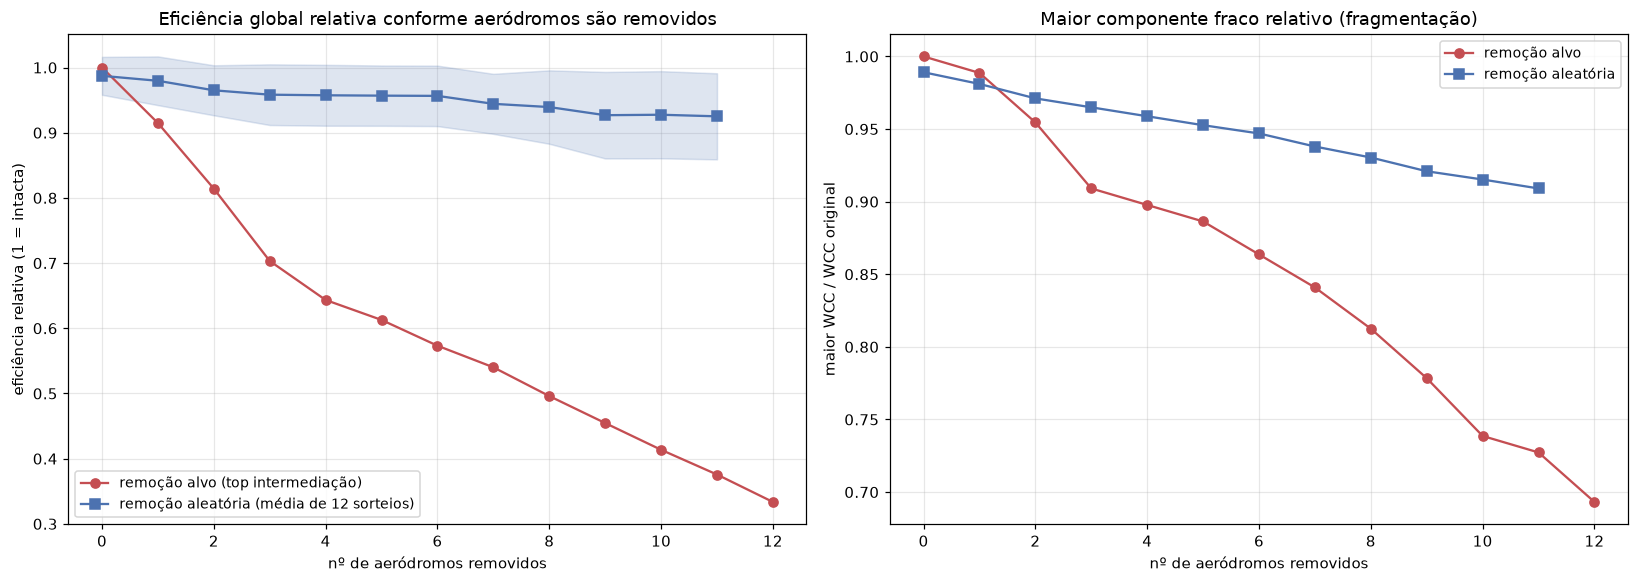

,k,eficiencia_alvo,wcc_alvo,eficiencia_aleatoria,eficiencia_aleatoria_desvio,wcc_aleatorio
0,0,1.0000,1.0000,0.9872,0.0291,0.9891
1,1,0.9148,0.9886,0.9796,0.0373,0.9811
2,2,0.8142,0.9545,0.9650,0.0383,0.9711
3,3,0.7032,0.9091,0.9583,0.0465,0.9650
4,4,0.6434,0.8977,0.9574,0.0467,0.9588
5,5,0.6128,0.8864,0.9568,0.0462,0.9527
6,6,0.5733,0.8636,0.9565,0.0464,0.9470
7,7,0.5402,0.8409,0.9443,0.0460,0.9380
8,8,0.4961,0.8125,0.9393,0.0563,0.9304
9,9,0.4547,0.7784,0.9269,0.0664,0.9209


In [21]:

curva_alvo = M.curva_remocao_alvo(g, cent.sort_values("intermediacao", ascending=False).icao.tolist(), k_max=12)
curva_aleatoria = M.curva_remocao_aleatoria(g, k_max=12, sorteios=12, seed=42)
comparacao_curvas = curva_alvo[["k", "eficiencia_relativa", "maior_wcc_relativo"]].rename(
    columns={"eficiencia_relativa": "eficiencia_alvo", "maior_wcc_relativo": "wcc_alvo"}).assign(
    eficiencia_aleatoria=curva_aleatoria.eficiencia_relativa_media,
    eficiencia_aleatoria_desvio=curva_aleatoria.eficiencia_relativa_desvio,
    wcc_aleatorio=curva_aleatoria.maior_wcc_relativo_medio)
comparacao_curvas.to_csv(RESULTADOS / "falha_curvas.csv", index=False)

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.4))
eixos[0].plot(comparacao_curvas.k, comparacao_curvas.eficiencia_alvo, marker="o",
              color="#c44e52", label="remoção alvo (top intermediação)")
eixos[0].plot(comparacao_curvas.k, comparacao_curvas.eficiencia_aleatoria, marker="s",
              color="#4c72b0", label="remoção aleatória (média de 12 sorteios)")
eixos[0].fill_between(comparacao_curvas.k,
                      comparacao_curvas.eficiencia_aleatoria - comparacao_curvas.eficiencia_aleatoria_desvio,
                      comparacao_curvas.eficiencia_aleatoria + comparacao_curvas.eficiencia_aleatoria_desvio,
                      color="#4c72b0", alpha=0.18)
eixos[0].set_title("Eficiência global relativa conforme aeródromos são removidos")
eixos[0].set_xlabel("nº de aeródromos removidos"); eixos[0].set_ylabel("eficiência relativa (1 = intacta)")
eixos[0].legend(fontsize=9)

eixos[1].plot(comparacao_curvas.k, comparacao_curvas.wcc_alvo, marker="o", color="#c44e52",
              label="remoção alvo")
eixos[1].plot(comparacao_curvas.k, comparacao_curvas.wcc_aleatorio, marker="s", color="#4c72b0",
              label="remoção aleatória")
eixos[1].set_title("Maior componente fraco relativo (fragmentação)")
eixos[1].set_xlabel("nº de aeródromos removidos"); eixos[1].set_ylabel("maior WCC / WCC original")
eixos[1].legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "17_falha_curvas.png", bbox_inches="tight")
plt.show()
comparacao_curvas.round(4)


**Leitura.** Com 12 remoções, o ataque informado (pelos maiores de intermediação) derruba
a eficiência para ~1/3 do original, enquanto a remoção aleatória de 12 aeródromos custa
~7%. A malha tem **alvos preferenciais**: não é robusta a falha escolhida, mas é
relativamente tolerante a falha aleatória — o resultado clássico de rede de cauda longa
(e a razão de a pergunta valer a pena: o operador dos hubs errados custa caro). A curva
da fragmentação mostra que o maior componente resiste mais tempo: o que desaba primeiro é
o **alcance médio**, não a mera existência de um caminho entre as pontas.

## 12. Arestas críticas e rotas alternativas

Fechando a pergunta: quais **rotas** não podem cair e, sem elas, qual caminho resta?

In [22]:

ac = M.arestas_criticas(g, k=15)
ac.to_csv(RESULTADOS / "arestas_criticas.csv", index=False)
ac.round(4)


,origem,destino,intermediacao_aresta,decolagens,passageiros,conecta_sem_aresta,saltos_sem_aresta,ponte_na_projecao
0,SBKP,SBEG,0.0140,1953.0,158853.0,True,2.0,False
1,SBEG,SBKP,0.0127,2029.0,170443.0,True,2.0,False
2,SBCF,SBEG,0.0118,399.0,53723.0,True,2.0,False
3,SBEG,SBUY,0.0113,465.0,24077.0,False,NaN,False
4,SBTT,SBEG,0.0113,496.0,32172.0,False,NaN,False
5,SBEG,SBCF,0.0101,395.0,58764.0,True,2.0,False
6,SBKP,SBBE,0.0094,1151.0,144295.0,True,2.0,False
7,SBEG,SBIH,0.0092,157.0,8092.0,True,2.0,False
8,SBRF,SBEG,0.0087,574.0,62706.0,True,2.0,False
9,SBIH,SBEG,0.0084,157.0,8500.0,True,3.0,False


**Leitura.** O topo da intermediação de aresta é um único tema: **toda rota que sai ou
chega em Manaus** (o corredor `SBKP↔SBEG` lidera nas duas direções, com 0,014/0,013),
seguido das conexões SBEG–SBCF, SBEG–SBUY, SBTT–SBEG. Duas observações finas:

- nenhuma das 15 rotas mais intermediadas é **ponte** da projeção: mesmo as rotas mais
  críticas têm caminho alternativo (coluna `saltos_sem_aresta` = 2, ou seja, +1 salto);
- a exceção são duas relações direcionais cujo caminho **desaparece** quando a aresta cai:
  `SBEG→SBUY` (Coari, AM — sem esse voo não há rota de Manaus a Coari) e `SBTT→SBEG`
  (Tabatinga, cuja **única** rota de saída é essa: removeu, ficou sem caminho nenhum).

O volume não explica a lista: SBKP–SBEG tem 1.953 decolagens, mas SBCF–SBKP tem 3.171 e
aparece em 14º. A intermediação de aresta mede **passagem**, não tamanho — é a mesma lição
do lado dos nós.

In [23]:

pares_sbkp = M.pares_afetados(g, no="SBKP")
pares_sbkp.to_csv(RESULTADOS / "rotas_alternativas_SBKP.csv", index=False)
print(f"SBKP fora: {len(pares_sbkp)} pares (dirigidos) tinham caminho mais curto passando por ele")
print(f"  perdem ligação total: {(~pares_sbkp.sobrou_caminho).sum()} "
      f"({(~pares_sbkp.sobrou_caminho).mean():.0%})")
print(f"  ganham desvio com alternativa: {pares_sbkp.sobrou_caminho.sum()}")
print()
visao = pares_sbkp[pares_sbkp.sobrou_caminho].nlargest(8, "delta_saltos")
visao[["origem", "destino", "saltos_antes", "saltos_depois", "km_antes", "km_depois", "caminho_depois"]]


SBKP fora: 5009 pares (dirigidos) tinham caminho mais curto passando por ele
  perdem ligação total: 1545 (31%)
  ganham desvio com alternativa: 3464



,origem,destino,saltos_antes,saltos_depois,km_antes,km_depois,caminho_depois
1545,SSKW,SBPB,2,4.0,4295.6,3996.6,SSKW -> SBCY -> SBBR -> SBBE -> SBPB
1546,SBVH,SBPB,2,4.0,4097.1,3798.6,SBVH -> SBCY -> SBBR -> SBBE -> SBPB
1547,SBCR,SBTF,2,4.0,4068.9,4622.2,SBCR -> SBAE -> SBCF -> SBEG -> SBTF
1548,SBBV,SBMI,2,4.0,3669.6,3958.9,SBBV -> SBBE -> SBCF -> SBJR -> SBMI
1549,SWLC,SBTF,2,4.0,3588.2,3550.5,SWLC -> SBRP -> SBBR -> SBEG -> SBTF
1550,SBCP,SBTF,2,4.0,3505.9,4515.5,SBCP -> SBRJ -> SBBE -> SBEG -> SBTF
1551,SBTF,SBCP,2,4.0,3505.9,3631.3,SBTF -> SBEG -> SBBR -> SBRJ -> SBCP
1552,SBTF,SNCP,2,4.0,3496.6,4881.1,SBTF -> SBEG -> SBBE -> SBSP -> SNCP


**Leitura (SBKP).** Dos 5.009 pares que usavam Campinas, **1.545 (31%) perdem o caminho
por completo** — não é "desvio": é desconexão. Os 3.464 que restam alongam até +2 saltos:
Cacoal→Parnaíba e Vilhena→Parnaíba passam de 2 para 4, Corumbá→Tefé de 2 para 4 — o
interior da Amazônia/ Centro-Oeste ganha uma volta pelo tronco. É essa diferença que
separa "gargalo" de "ponto de corte": o gargalo atrasa, o corte isola — e SBKP faz as
duas coisas ao mesmo tempo, dependendo do par.

In [24]:

pares_sbeg = M.pares_afetados(g, no="SBEG")
pares_sbeg.to_csv(RESULTADOS / "rotas_alternativas_SBEG.csv", index=False)
print(f"SBEG fora: {len(pares_sbeg)} pares tinham caminho mais curto passando por Manaus")
print(f"  perdem ligação total: {(~pares_sbeg.sobrou_caminho).sum()} "
      f"({(~pares_sbeg.sobrou_caminho).mean():.0%})")
com_alternativa = pares_sbeg[pares_sbeg.sobrou_caminho]
print(f"  com alternativa: {len(com_alternativa)} | desvio médio: "
      f"{com_alternativa.delta_saltos.mean():.2f} salto (pior: {com_alternativa.delta_saltos.max():.0f})")

exemplo = com_alternativa.nlargest(1, "delta_saltos").iloc[0]
caminho_antes = exemplo.caminho_antes.split(" -> ")
caminho_depois = exemplo.caminho_depois.split(" -> ")
print(f"exemplo para o mapa: {exemplo.origem} -> {exemplo.destino} "
      f"({exemplo.saltos_antes} -> {exemplo.saltos_depois} saltos)")
print("  antes:", " -> ".join(caminho_antes))
print("  depois:", " -> ".join(caminho_depois))


SBEG fora: 5874 pares tinham caminho mais curto passando por Manaus
  perdem ligação total: 3374 (57%)
  com alternativa: 2500 | desvio médio: 0.39 salto (pior: 3)
exemplo para o mapa: SWTP -> SBEK (3 -> 6.0 saltos)
  antes: SWTP -> SBEG -> SBIH -> SBEK
  depois: SWTP -> SBTF -> SBKP -> SBBE -> SBMA -> SBIH -> SBEK


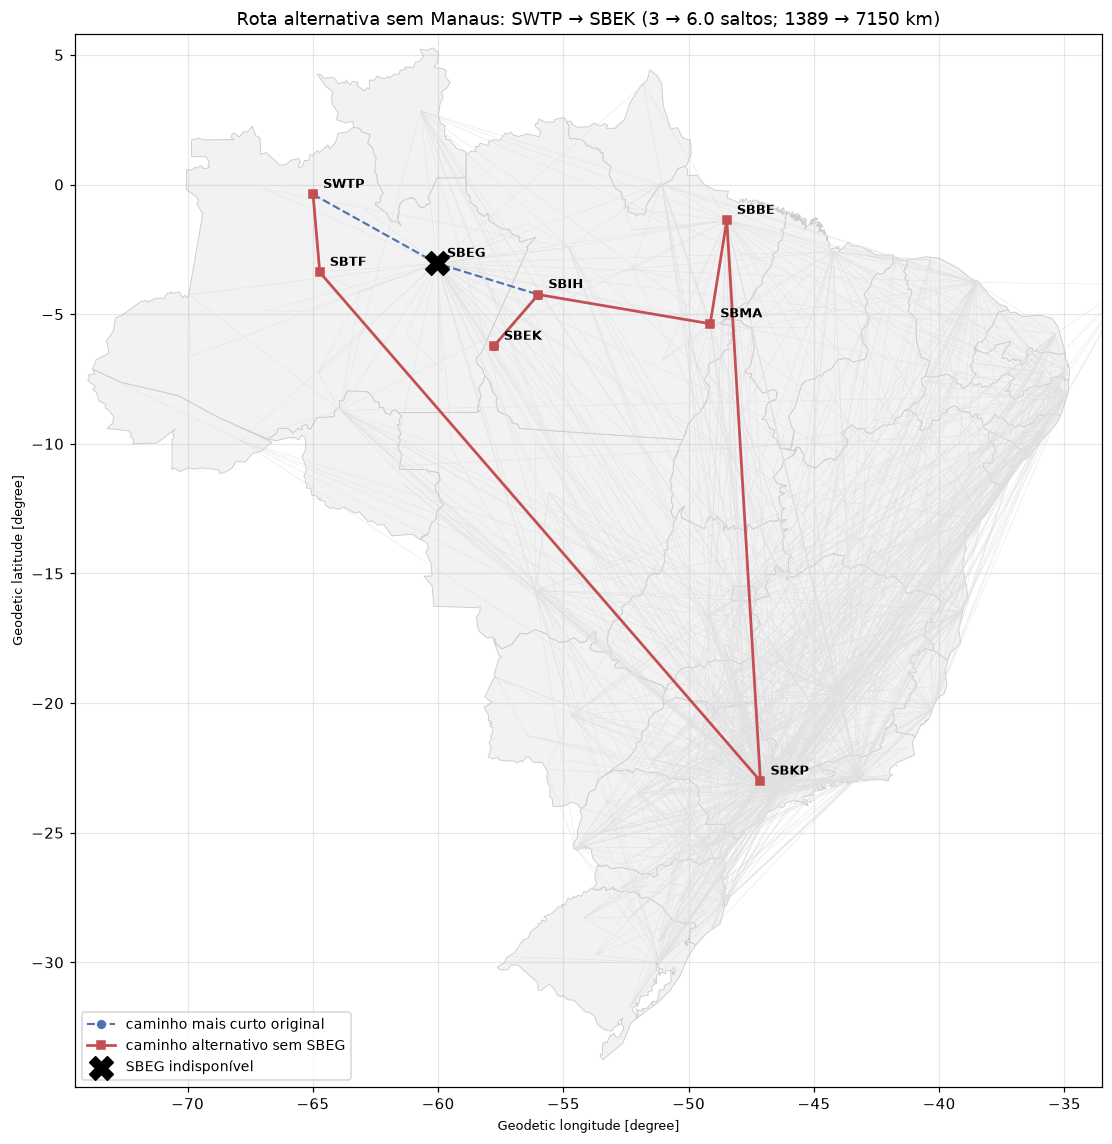

In [25]:

fig, eixo = plt.subplots(figsize=(11, 10.5))
M.fundo_mapa(eixo)
for u, v in h.edges():
    eixo.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#e0e0e0",
              linewidth=0.3, zorder=1)
eixo.plot([pos[n][0] for n in caminho_antes], [pos[n][1] for n in caminho_antes],
          "--o", color="#4c72b0", linewidth=1.4, markersize=5, label="caminho mais curto original", zorder=3)
eixo.plot([pos[n][0] for n in caminho_depois], [pos[n][1] for n in caminho_depois],
          "-s", color="#c44e52", linewidth=1.8, markersize=5.5, label="caminho alternativo sem SBEG", zorder=4)
eixo.scatter(*pos["SBEG"], marker="X", s=240, color="black", zorder=5, label="SBEG indisponível")
for n in set(caminho_antes) | set(caminho_depois):
    eixo.annotate(n, (pos[n][0] + 0.4, pos[n][1] + 0.25), fontsize=8.5, fontweight="bold", zorder=6)
eixo.set_title(f"Rota alternativa sem Manaus: {exemplo.origem} → {exemplo.destino} "
               f"({exemplo.saltos_antes} → {exemplo.saltos_depois} saltos; "
               f"{exemplo.km_antes:.0f} → {exemplo.km_depois:.0f} km)")
eixo.set_xlim(-74.5, -33.5); eixo.set_ylim(-34.8, 5.8); eixo.set_aspect(1.035)
eixo.legend(loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "18_rota_alternativa.png", bbox_inches="tight")
plt.show()


**Leitura (SBEG).** Manaus é o caso radical: **3.374 dos 5.874 pares que usavam Manaus
(57%) perdem ligação por completo** — mais da metade sem alternativa nenhuma. Os 2.500
que têm costumam manter o número de saltos (desvio médio 0,39; pior caso +3): a malha
densa às vezes oferece caminho equivalente — o problema não é o atraso, é o **corte**.
E no exemplo do mapa, o preço aparece: Santa Isabel do Rio Negro → Jacareacanga
(3 → 6 saltos) só se resolve **dando a volta pelo país** — Tefé → Campinas → Belém →
Marabá → Jacareacanga. Para o passageiro do Amazonas, a "alternativa que resta" sai da
região e volta: é o retrato de por que a redundância no Norte é infraestrutura, não
excesso.

## 13. Ranking de criticidade

Juntando as medidas (intermediação, core number, perda de eficiência medida, aeródromos
isolados) em uma tabela única — o produto que a pergunta pede.

In [26]:

ranking = (cent.merge(kcore[["icao", "core_number"]], on="icao")
           .merge(impactos[["icao_removido", "perda_eficiencia_relativa", "aerodromos_sem_rota_saida",
                            "lista_sem_rota_saida"]].rename(columns={"icao_removido": "icao"}),
                  on="icao", how="left"))
ranking["testado"] = ranking.icao.isin(candidatos)
ranking["top10_intermediacao"] = ranking.icao.isin(top10_inter)
ranking = ranking.sort_values("intermediacao", ascending=False).reset_index(drop=True)
ranking.to_csv(RESULTADOS / "ranking_criticidade.csv", index=False)

ranking.head(15)[["icao", "nome", "uf", "regiao", "grau_total", "passageiros_total",
                  "intermediacao", "core_number", "perda_eficiencia_relativa", "aerodromos_sem_rota_saida"]].round(4)


,icao,nome,uf,regiao,grau_total,passageiros_total,intermediacao,core_number,perda_eficiencia_relativa,aerodromos_sem_rota_saida
0,SBKP,CAMPINAS,SP,SUDESTE,181,11654910.0,0.2519,18,0.0852,3.0
1,SBCF,CONFINS,MG,SUDESTE,156,12339499.0,0.1997,18,0.0878,7.0
2,SBEG,MANAUS,AM,NORTE,90,2961478.0,0.1805,18,0.1027,3.0
3,SBRF,RECIFE,PE,NORDESTE,108,9242285.0,0.1169,18,0.0636,5.0
4,SBBE,BELÉM,PA,NORTE,76,3714377.0,0.0923,18,0.0321,2.0
5,SBGR,GUARULHOS,SP,SUDESTE,134,29872406.0,0.0746,18,0.0182,1.0
6,SBFZ,FORTALEZA,CE,NORDESTE,73,5556875.0,0.0567,18,0.0374,4.0
7,SBCT,SÃO JOSÉ DOS PINHAIS,PR,SUL,84,5846695.0,0.0513,18,0.0203,2.0
8,SBSV,SALVADOR,BA,NORDESTE,76,7304233.0,0.0505,18,0.0319,0.0
9,SBJD,JUNDIAÍ,SP,SUDESTE,50,0.0,0.0454,15,0.0242,0.0


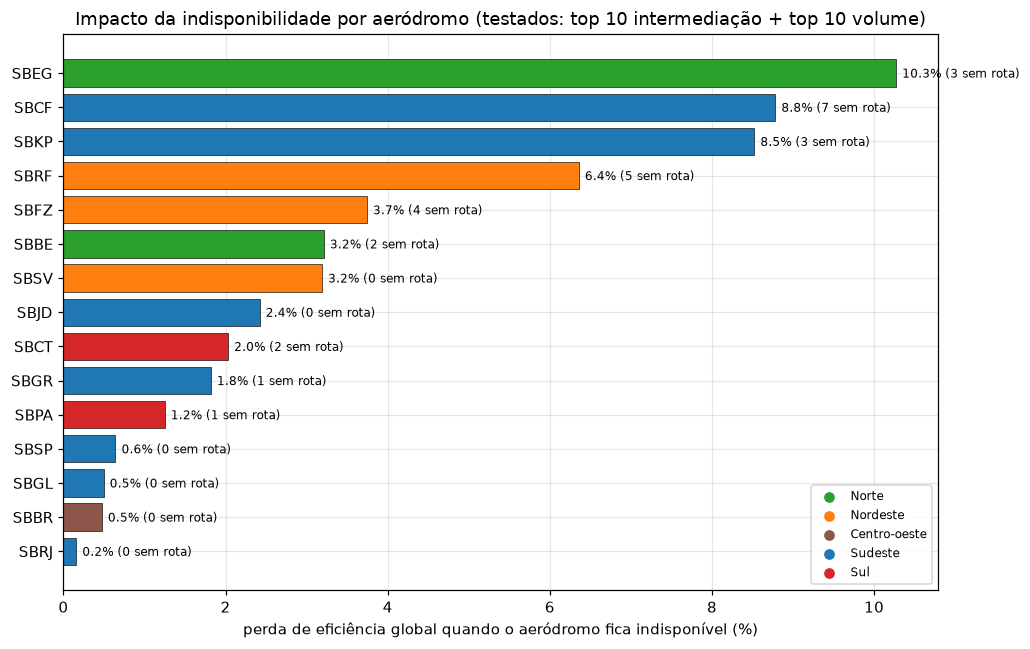

In [27]:

fig, eixo = plt.subplots(figsize=(9.5, 6))
presentes = impactos.sort_values("perda_eficiencia_relativa", ascending=True)
cores_barras = [regioes[r] for r in cent.set_index("icao").loc[presentes.icao_removido, "regiao"]]
eixo.barh(presentes.icao_removido, 100 * presentes.perda_eficiencia_relativa,
          color=cores_barras, edgecolor="black", linewidth=0.4)
for icao, valor, sem_rota in zip(presentes.icao_removido, 100 * presentes.perda_eficiencia_relativa,
                                 presentes.aerodromos_sem_rota_saida):
    eixo.annotate(f"{valor:.1f}% ({sem_rota} sem rota)", (valor, icao), xytext=(4, -3),
                  textcoords="offset points", fontsize=8)
for regiao, cor in regioes.items():
    eixo.scatter([], [], color=cor, label=regiao.capitalize())
eixo.set_xlabel("perda de eficiência global quando o aeródromo fica indisponível (%)")
eixo.set_title("Impacto da indisponibilidade por aeródromo (testados: top 10 intermediação + top 10 volume)")
eixo.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURAS / "19_ranking_criticidade.png", bbox_inches="tight")
plt.show()


## Resposta à pergunta do projeto

**Pergunta:** *quais aeroportos e rotas são críticos para a conectividade da malha aérea
doméstica brasileira e, quando um deles cai, quais rotas alternativas restam?*

**Resposta em três níveis:**

1. **Aeródromos críticos (de verdade):** `SBKP` (Campinas, intermediação 0,25), `SBCF`
   (Confins, 0,20) e `SBEG` (Manaus, 0,18). Mas atenção à diferença entre **passagem** e
   **efeito**: na intermediação Campinas lidera; no impacto medido por remoção, Manaus
   lidera — 10,3% da eficiência global, 5 componentes, e SBTT/SWBC/SWBR **sem nenhuma
   rota de saída**; Confins tira 8,8% e isola 7 aeródromos; Campinas, 8,5% e 3. Os maiores
   em volume (SBGR, SBSP, SBBR, SBGL) custam ≤ 1,8% — têm alternativas. Na rede,
   *crítico = único*, não *maior*.
2. **Rotas críticas:** o corredor `SBKP↔SBEG` lidera a intermediação de aresta nas duas
   direções (0,014 / 0,013) — toda a lista do topo gravita em Manaus. Nenhuma das 15
   rotas mais críticas é ponte (o tronco tem alternativa de +1 salto), mas duas relações
   direcionais perdem o caminho por completo (`SBEG→SBUY`, `SBTT→SBEG`) e as 22 pontes da
   projeção são ligações únicas de aeródromos pequenos.
3. **Alternativas que restam:** para os gargalos do Sudeste (SBKP, SBCF), quem tem
   alternativa alonga até +2 saltos (Cacoal→Parnaíba 2→4; Corumbá→Tefé 2→4). Para o
   Norte (SBEG), **57% não têm nenhuma** — e quem tem dá a volta pelo país (Santa Isabel
   do Rio Negro→Jacareacanga: 3→6 saltos, via Tefé–Campinas–Belém). Consequência para o
   investimento: no Norte, rota redundante é infraestrutura, não excesso.

**Consequência prática:** na rede, *crítico = único*, não *maior*. A malha tolera a
queda dos maiores terminais (SP concentra alternativas) e não tolera a queda dos
"portões" regionais e das rotas de passagem — exatamente o oposto do que a intuição
de volume sugere.

## Limitações e artefatos reconhecidos

Limitações de modelagem/dados (cada uma com a consequência que ela tem no resultado):

1. **Recorte e janela:** só malha doméstica, agregada no ano de 2025. A rede anual é a
   união de doze redes mensais: um aeródromo "presente no ano" pode operar só sazonalmente
   (janeiro isolado tem 158 nós; o ano tem 176). Um teste de emergência real seria por mês.
2. **`NATUREZA` da ANAC contraditória:** o campo marca rotas internas como
   `INTERNACIONAL`; usamos `PAÍS` das pontas, com diferença de 6 rotas (0,4%). Fica
   documentado que a base oficial tem esse erro.
3. **Voo ≠ rota:** `DECOLAGENS` é oferta agregada (linha não é voo); escala e frequência
   diária não estão no dado — a distância em saltos aproxima a experiência do passageiro,
   mas não a substitui.
4. **Distância:** a distância usada nas arestas é a geográfica (haversine) calculada das
   coordenadas (OurAirports); o campo `DISTÂNCIA VOADA (KM)` da ANAC tem 622 linhas nulas
   no recorte doméstico e serve de conferência (as duas concordam; ver `01_dados`).
5. **Projeção não dirigida:** triângulos, clustering, k-core, k-truss, pontes e
   articulações são computados na projeção — um ciclo dirigido de 3 nós vira triângulo.
   Nas medidas dirigidas (distâncias, eficiência, SCC, centralidades, falha) usamos o
   digrafo.
6. **Intermediação sem peso:** é a medida anunciada; a variante por distância (km) dá
   quase o mesmo ranking (Spearman 0,905); a variante por frequência muda o líder (SBGR
   assume, Spearman 0,656) e sobe SBEG/SBRF/SBBE. As três concordam que existe um pequeno
   conjunto de gargalos; o que muda é quem está no topo — leitura registrada na seção 3.
7. **Amostragem:** não há — o dado é censitário no recorte (todos os voos domésticos
   registrados). O experimento de bola de neve existe para mostrar o que aconteceria com
   dado amostrado/parcial (artefato documentado).
8. **Voo não regular na cauda:** os voos não regulares/improdutivos são 32% das linhas
   mas só 3,5% das decolagens; excluí-los derrubaria 15 aeródromos que só têm esse tipo
   de operação. Ficam dentro (o voo existiu), com a ressalva: um aeródromo que só tem
   táxi aéreo é dependente de empresa pequena, não de malha comercial regular.
9. **Coordenadas:** OurAirports (nome municipal diferente da ANAC em alguns casos;
   aproximação de aeródromo) — afeta só os mapas e as distâncias haversine em pequena
   escala, não a topologia.

Artefatos de medida (não são conclusão):

- aeródromos de grau 1–2 têm clustering e Jaccard = 1 por construção (sem espaço
  para variar);
- a cauda de grau 1 é dominada por decolagens de posicionamento (ex.: SBBP→SBSJ, 1 voo,
  0 passageiro) — ruído de registro com peso ínfimo;
- `SBBP` aparece como o único nó fora do maior SCC por esse mesmo motivo.

## Próximos passos

1. **Mês a mês:** repetir a análise de falha por mês para achar sazonalidade real
   (norte-sul de férias, safra) — a rede anual esconde isso.
2. **Falha de aresta por companhia:** usar `EMPRESA (SIGLA)` para a pergunta de
   operação — se a empresa X sai do mercado, o que cai? (O bipartido já está pronto para
   isso.)
3. **Capacidade:** cruzar com a infra-estrutura do aeródromo (pista, terminal) para
   checar se a alternativa que "existe" na malha suporta o fluxo remanejado —
   conectividade ≠ capacidade.
4. **Modelo com o internacional:** incluir o grau de exposição internacional dos hubs, que
   o recorte doméstico deixa de fora.
5. **Comparação temporal:** 2024 e 2025 lado a lado para separar estrutura de
   flutuação anual.